# $T(0^+)$-dependent safe-domain boundaries

The latest successful `26-08-09` manifest contains twelve cold $A=1$ ray roots and twelve fixed-$T(0^+)$ solutions of $\Delta h=0$ for each of $T(0^+)=1,10,50$ MeV, including the $0^\circ$ and $90^\circ$ boundary anchors. Every gray-region boundary is reconstructed from those newly downloaded roots. The two phase-coexistence curves are calculated once with the current EoS and cached locally; the entropy-equality contour reuses only the matching numerical-$I_2$ entropy map, never its older $A$ boundary.

Loaded 12 cold A=1 roots from /Users/janshao/NSM_related/new_paper_calculations/26-08-09/T0plus-contour-domain.npy
Loaded Delta h=0 roots: 36
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-11/T0plus-safe-domain-gray-regions-26-08-09.png


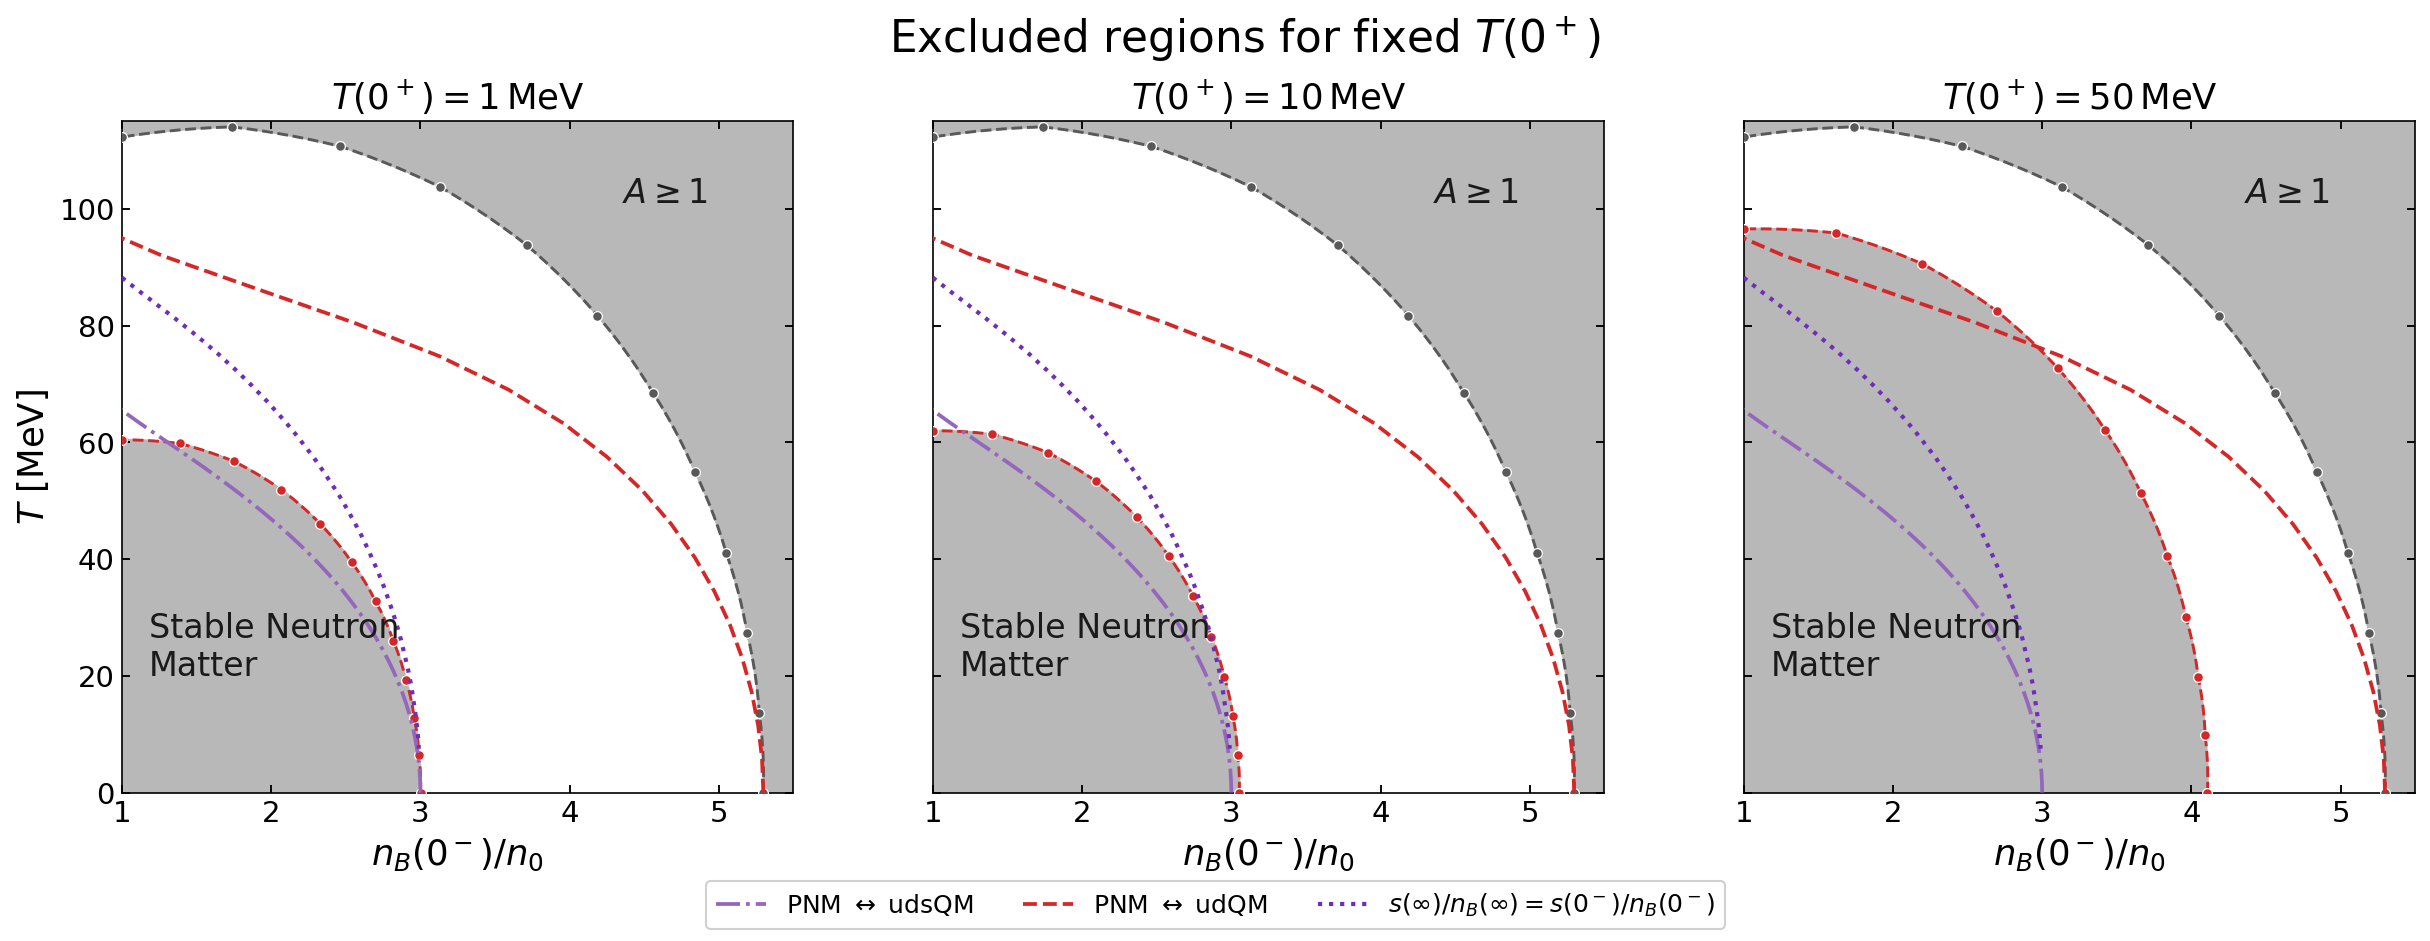

In [1]:
# Tunable plotting parameters
BOUNDARY_MANIFEST_PATH = "new_paper_calculations/26-08-09/T0plus-contour-domain.npy"
ENTROPY_PAYLOAD_PATH = "new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy"
OVERLAY_CACHE_PATH = "local_analysis_results/26SU-11/phase-overlay-curves.npy"
OVERLAY_FORCE_RECOMPUTE = False
OVERLAY_UDS_TEMPERATURE_COUNT = 61
OVERLAY_UD_TEMPERATURE_COUNT = 21
T0PLUS_PANEL_VALUES_MEV = (1.0, 10.0, 50.0)
BOUNDARY_INTERPOLATION_SAMPLES = 241
FIGURE_SIZE = (16.5, 6.2)
FIGURE_DPI = 150
EXPORT_DPI = 220
CONSTRAINED_LAYOUT = True
BACKGROUND_COLOR = "white"
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.0
GAP_SHADE_COLOR = "0.72"
A_SHADE_COLOR = "0.72"
SHADE_ALPHA = 1.0
SHADE_ZORDER = 0
GAP_BOUNDARY_COLOR = "#d62728"
GAP_BOUNDARY_STYLE = "--"
GAP_BOUNDARY_WIDTH = 1.4
A_BOUNDARY_COLOR = "0.35"
A_BOUNDARY_STYLE = "--"
A_BOUNDARY_WIDTH = 1.4
BOUNDARY_ZORDER = 2
RAW_POINT_COLOR = "#d62728"
RAW_POINT_MARKER = "o"
RAW_POINT_SIZE = 22.0
RAW_POINT_EDGE_COLOR = "white"
RAW_POINT_EDGE_WIDTH = 0.6
RAW_POINT_ZORDER = 3
A_RAW_POINT_COLOR = "0.35"
UDS_TRANSITION_COLOR = "#9467bd"
UDS_TRANSITION_STYLE = "-."
UDS_TRANSITION_WIDTH = 1.8
UD_TRANSITION_COLOR = "#d62728"
UD_TRANSITION_STYLE = "--"
UD_TRANSITION_WIDTH = 1.8
ENTROPY_BOUNDARY_COLOR = "#6f2dbd"
ENTROPY_BOUNDARY_STYLE = ":"
ENTROPY_BOUNDARY_WIDTH = 2.0
THERMODYNAMIC_CURVE_ZORDER = 4
PANEL_TITLE_FONT_SIZE = 17
PANEL_TITLE_PAD = 6
AXIS_LABEL_FONT_SIZE = 17
TICK_LABEL_FONT_SIZE = 14
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
A_TEXT = r"$A\geq 1$"
A_TEXT_POSITION = (4.35, 101.0)
GAP_TEXT = "Stable Neutron\nMatter"
GAP_TEXT_POSITION = (1.18, 20.0)
REGION_TEXT_COLOR = "0.10"
REGION_TEXT_FONT_SIZE = 16
TEXT_ZORDER = 4
SUPTITLE = r"Excluded regions for fixed $T(0^+)$"
SUPTITLE_FONT_SIZE = 21
FIGURE_LEGEND_LOCATION = "outside lower center"
FIGURE_LEGEND_COLUMNS = 3
FIGURE_LEGEND_FONT_SIZE = 12
FIGURE_LEGEND_FRAME_ALPHA = 0.92
OUTPUT_PNG = "local_analysis_results/26SU-11/T0plus-safe-domain-gray-regions-26-08-09.png"
OUTPUT_PDF = "local_analysis_results/26SU-11/T0plus-safe-domain-gray-regions-26-08-09.pdf"

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

root = Path.cwd()
manifest_path = root / BOUNDARY_MANIFEST_PATH
entropy_payload_path = root / ENTROPY_PAYLOAD_PATH
overlay_cache_path = root / OVERLAY_CACHE_PATH
helper_path = root / "new_paper_calculations/26-08-07"
if str(helper_path) not in sys.path:
    sys.path.insert(0, str(helper_path))
from _phase_overlay_curves import load_or_calculate_overlay_curves

manifest = np.load(manifest_path, allow_pickle=True).item()
semi_boundary = manifest["boundary_diagnostics"]["semi_analytic"]
transform = manifest["transform"]
density_origin = float(transform["density_origin_over_n0"])
density_scale = float(transform["density_scale_over_n0"])
temperature_scale = float(transform["temperature_scale_MeV"])
A_records = list(semi_boundary["A_curve_records"])
gap_records_by_T0plus = semi_boundary["gap_curve_records_by_T0plus"]
overlay_curves = load_or_calculate_overlay_curves(
    manifest_path=manifest_path,
    entropy_payload_path=entropy_payload_path,
    cache_path=overlay_cache_path,
    temperature_limits_MeV=Y_LIMITS_MEV,
    uds_temperature_count=OVERLAY_UDS_TEMPERATURE_COUNT,
    ud_temperature_count=OVERLAY_UD_TEMPERATURE_COUNT,
    force_recompute=OVERLAY_FORCE_RECOMPUTE,
)
uds_transition_density = np.asarray(overlay_curves["uds_nB_0minus_over_n0"], dtype=float)
uds_transition_temperature = np.asarray(overlay_curves["uds_temperature_MeV"], dtype=float)
ud_transition_density = np.asarray(overlay_curves["ud_nB_0minus_over_n0"], dtype=float)
ud_transition_temperature = np.asarray(overlay_curves["ud_temperature_MeV"], dtype=float)
entropy_density = np.asarray(overlay_curves["entropy_nB_0minus_over_n0"], dtype=float)
entropy_temperature = np.asarray(overlay_curves["entropy_temperature_MeV"], dtype=float)
entropy_jump = np.ma.masked_invalid(
    np.asarray(overlay_curves["entropy_jump_per_baryon"], dtype=float)
)

def ray_interpolated_curve(records):
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta_roots = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho_roots = np.asarray([row["rho"] for row in ordered], dtype=float)
    theta_curve = np.linspace(0.0, 0.5 * np.pi, BOUNDARY_INTERPOLATION_SAMPLES)
    rho_curve = np.interp(theta_curve, theta_roots, rho_roots)
    density_curve = density_origin + density_scale * rho_curve * np.cos(theta_curve)
    temperature_curve = temperature_scale * rho_curve * np.sin(theta_curve)
    raw_density = np.asarray([row["nB_over_n0"] for row in ordered], dtype=float)
    raw_temperature = np.asarray([row["T_MeV"] for row in ordered], dtype=float)
    return density_curve, temperature_curve, raw_density, raw_temperature

if len(A_records) < 2:
    raise RuntimeError("The 26-08-09 manifest does not contain enough cold A=1 roots")
missing = [value for value in T0PLUS_PANEL_VALUES_MEV if len(gap_records_by_T0plus.get(value, [])) < 2]
if missing:
    raise RuntimeError(f"Missing Delta h=0 roots for T(0+)={missing}")
A_density, A_temperature, A_raw_density, A_raw_temperature = ray_interpolated_curve(A_records)

figure, axes = plt.subplots(
    1,
    3,
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=BACKGROUND_COLOR,
    sharex=True,
    sharey=True,
)

for axis, T0plus in zip(axes.flat, T0PLUS_PANEL_VALUES_MEV):
    records = gap_records_by_T0plus[T0plus]
    gap_density, gap_temperature, raw_density, raw_temperature = ray_interpolated_curve(records)

    gap_polygon_x = np.concatenate((gap_density, (X_LIMITS[0], gap_density[0])))
    gap_polygon_y = np.concatenate((gap_temperature, (Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
    axis.fill(
        gap_polygon_x,
        gap_polygon_y,
        color=GAP_SHADE_COLOR,
        alpha=SHADE_ALPHA,
        zorder=SHADE_ZORDER,
    )
    A_polygon_x = np.concatenate((
        A_density,
        (X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], A_density[0]),
    ))
    A_polygon_y = np.concatenate((
        A_temperature,
        (Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]),
    ))
    axis.fill(
        A_polygon_x,
        A_polygon_y,
        color=A_SHADE_COLOR,
        alpha=SHADE_ALPHA,
        zorder=SHADE_ZORDER,
    )
    axis.plot(
        gap_density,
        gap_temperature,
        color=GAP_BOUNDARY_COLOR,
        linestyle=GAP_BOUNDARY_STYLE,
        linewidth=GAP_BOUNDARY_WIDTH,
        zorder=BOUNDARY_ZORDER,
    )
    axis.plot(
        A_density,
        A_temperature,
        color=A_BOUNDARY_COLOR,
        linestyle=A_BOUNDARY_STYLE,
        linewidth=A_BOUNDARY_WIDTH,
        zorder=BOUNDARY_ZORDER,
    )
    axis.plot(
        uds_transition_density,
        uds_transition_temperature,
        color=UDS_TRANSITION_COLOR,
        linestyle=UDS_TRANSITION_STYLE,
        linewidth=UDS_TRANSITION_WIDTH,
        zorder=THERMODYNAMIC_CURVE_ZORDER,
    )
    axis.plot(
        ud_transition_density,
        ud_transition_temperature,
        color=UD_TRANSITION_COLOR,
        linestyle=UD_TRANSITION_STYLE,
        linewidth=UD_TRANSITION_WIDTH,
        zorder=THERMODYNAMIC_CURVE_ZORDER,
    )
    entropy_finite = np.asarray(entropy_jump.compressed(), dtype=float)
    if entropy_finite.size and np.min(entropy_finite) <= 0.0 <= np.max(entropy_finite):
        axis.contour(
            entropy_density,
            entropy_temperature,
            entropy_jump,
            levels=(0.0,),
            colors=(ENTROPY_BOUNDARY_COLOR,),
            linestyles=(ENTROPY_BOUNDARY_STYLE,),
            linewidths=(ENTROPY_BOUNDARY_WIDTH,),
            zorder=THERMODYNAMIC_CURVE_ZORDER,
        )
    axis.scatter(
        A_raw_density,
        A_raw_temperature,
        color=A_RAW_POINT_COLOR,
        marker=RAW_POINT_MARKER,
        s=RAW_POINT_SIZE,
        edgecolor=RAW_POINT_EDGE_COLOR,
        linewidth=RAW_POINT_EDGE_WIDTH,
        zorder=RAW_POINT_ZORDER,
    )
    axis.scatter(
        raw_density,
        raw_temperature,
        color=RAW_POINT_COLOR,
        marker=RAW_POINT_MARKER,
        s=RAW_POINT_SIZE,
        edgecolor=RAW_POINT_EDGE_COLOR,
        linewidth=RAW_POINT_EDGE_WIDTH,
        zorder=RAW_POINT_ZORDER,
    )
    axis.text(
        *A_TEXT_POSITION,
        A_TEXT,
        color=REGION_TEXT_COLOR,
        fontsize=REGION_TEXT_FONT_SIZE,
        zorder=TEXT_ZORDER,
    )
    axis.text(
        *GAP_TEXT_POSITION,
        GAP_TEXT,
        color=REGION_TEXT_COLOR,
        fontsize=REGION_TEXT_FONT_SIZE,
        zorder=TEXT_ZORDER,
    )
    axis.set_xlim(*X_LIMITS)
    axis.set_ylim(*Y_LIMITS_MEV)
    axis.set_xscale(X_SCALE)
    axis.set_yscale(Y_SCALE)
    axis.set_box_aspect(BOX_ASPECT)
    axis.set_title(
        rf"$T(0^+)={T0plus:g}\,\mathrm{{MeV}}$",
        fontsize=PANEL_TITLE_FONT_SIZE,
        pad=PANEL_TITLE_PAD,
    )
    axis.tick_params(
        direction=TICK_DIRECTION,
        top=TICKS_TOP,
        right=TICKS_RIGHT,
        length=TICK_LENGTH,
        width=TICK_WIDTH,
        labelsize=TICK_LABEL_FONT_SIZE,
    )
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)

for axis in axes:
    axis.set_xlabel(r"$n_B(0^-)/n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
axes[0].set_ylabel(r"$T$ [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)
legend_handles = (
    Line2D(
        (0.0,), (0.0,), color=UDS_TRANSITION_COLOR, linestyle=UDS_TRANSITION_STYLE,
        linewidth=UDS_TRANSITION_WIDTH, label=r"PNM $\leftrightarrow$ udsQM",
    ),
    Line2D(
        (0.0,), (0.0,), color=UD_TRANSITION_COLOR, linestyle=UD_TRANSITION_STYLE,
        linewidth=UD_TRANSITION_WIDTH, label=r"PNM $\leftrightarrow$ udQM",
    ),
    Line2D(
        (0.0,), (0.0,), color=ENTROPY_BOUNDARY_COLOR, linestyle=ENTROPY_BOUNDARY_STYLE,
        linewidth=ENTROPY_BOUNDARY_WIDTH,
        label=r"$s(\infty)/n_B(\infty)=s(0^-)/n_B(0^-)$",
    ),
)
figure.legend(
    handles=legend_handles,
    loc=FIGURE_LEGEND_LOCATION,
    ncol=FIGURE_LEGEND_COLUMNS,
    fontsize=FIGURE_LEGEND_FONT_SIZE,
    framealpha=FIGURE_LEGEND_FRAME_ALPHA,
)

figure.suptitle(SUPTITLE, fontsize=SUPTITLE_FONT_SIZE)

output_png = root / OUTPUT_PNG
output_pdf = root / OUTPUT_PDF
output_png.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
figure.savefig(output_pdf, facecolor=BACKGROUND_COLOR)
print(f"Loaded {len(A_records)} cold A=1 roots from {manifest_path}")
print(f"Loaded Delta h=0 roots: {sum(len(gap_records_by_T0plus[value]) for value in T0PLUS_PANEL_VALUES_MEV)}")
print(f"Saved {output_png}")
plt.show()


# Full analytical, semi-analytical, and numerical contours

Each panel uses the same `26-08-09` adaptive domain for one fixed $T(0^+)$. Numerical $u_N^{\max}$ contours are solid, semi-analytical numerical-$I_2$ contours are dashed, and full analytical contours are dotted. Failed or unfinished numerical cells are masked rather than filled by interpolation. The downloaded numerical payload is a checkpoint containing 585 successful cells out of 800 and is marked `run_complete=False`.

Full analytical successes: 787/800
Semi-analytical successes: 779/800
Numerical successes: 585/800; run_complete=False
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-11/T0plus-three-method-contours-26-08-09.png


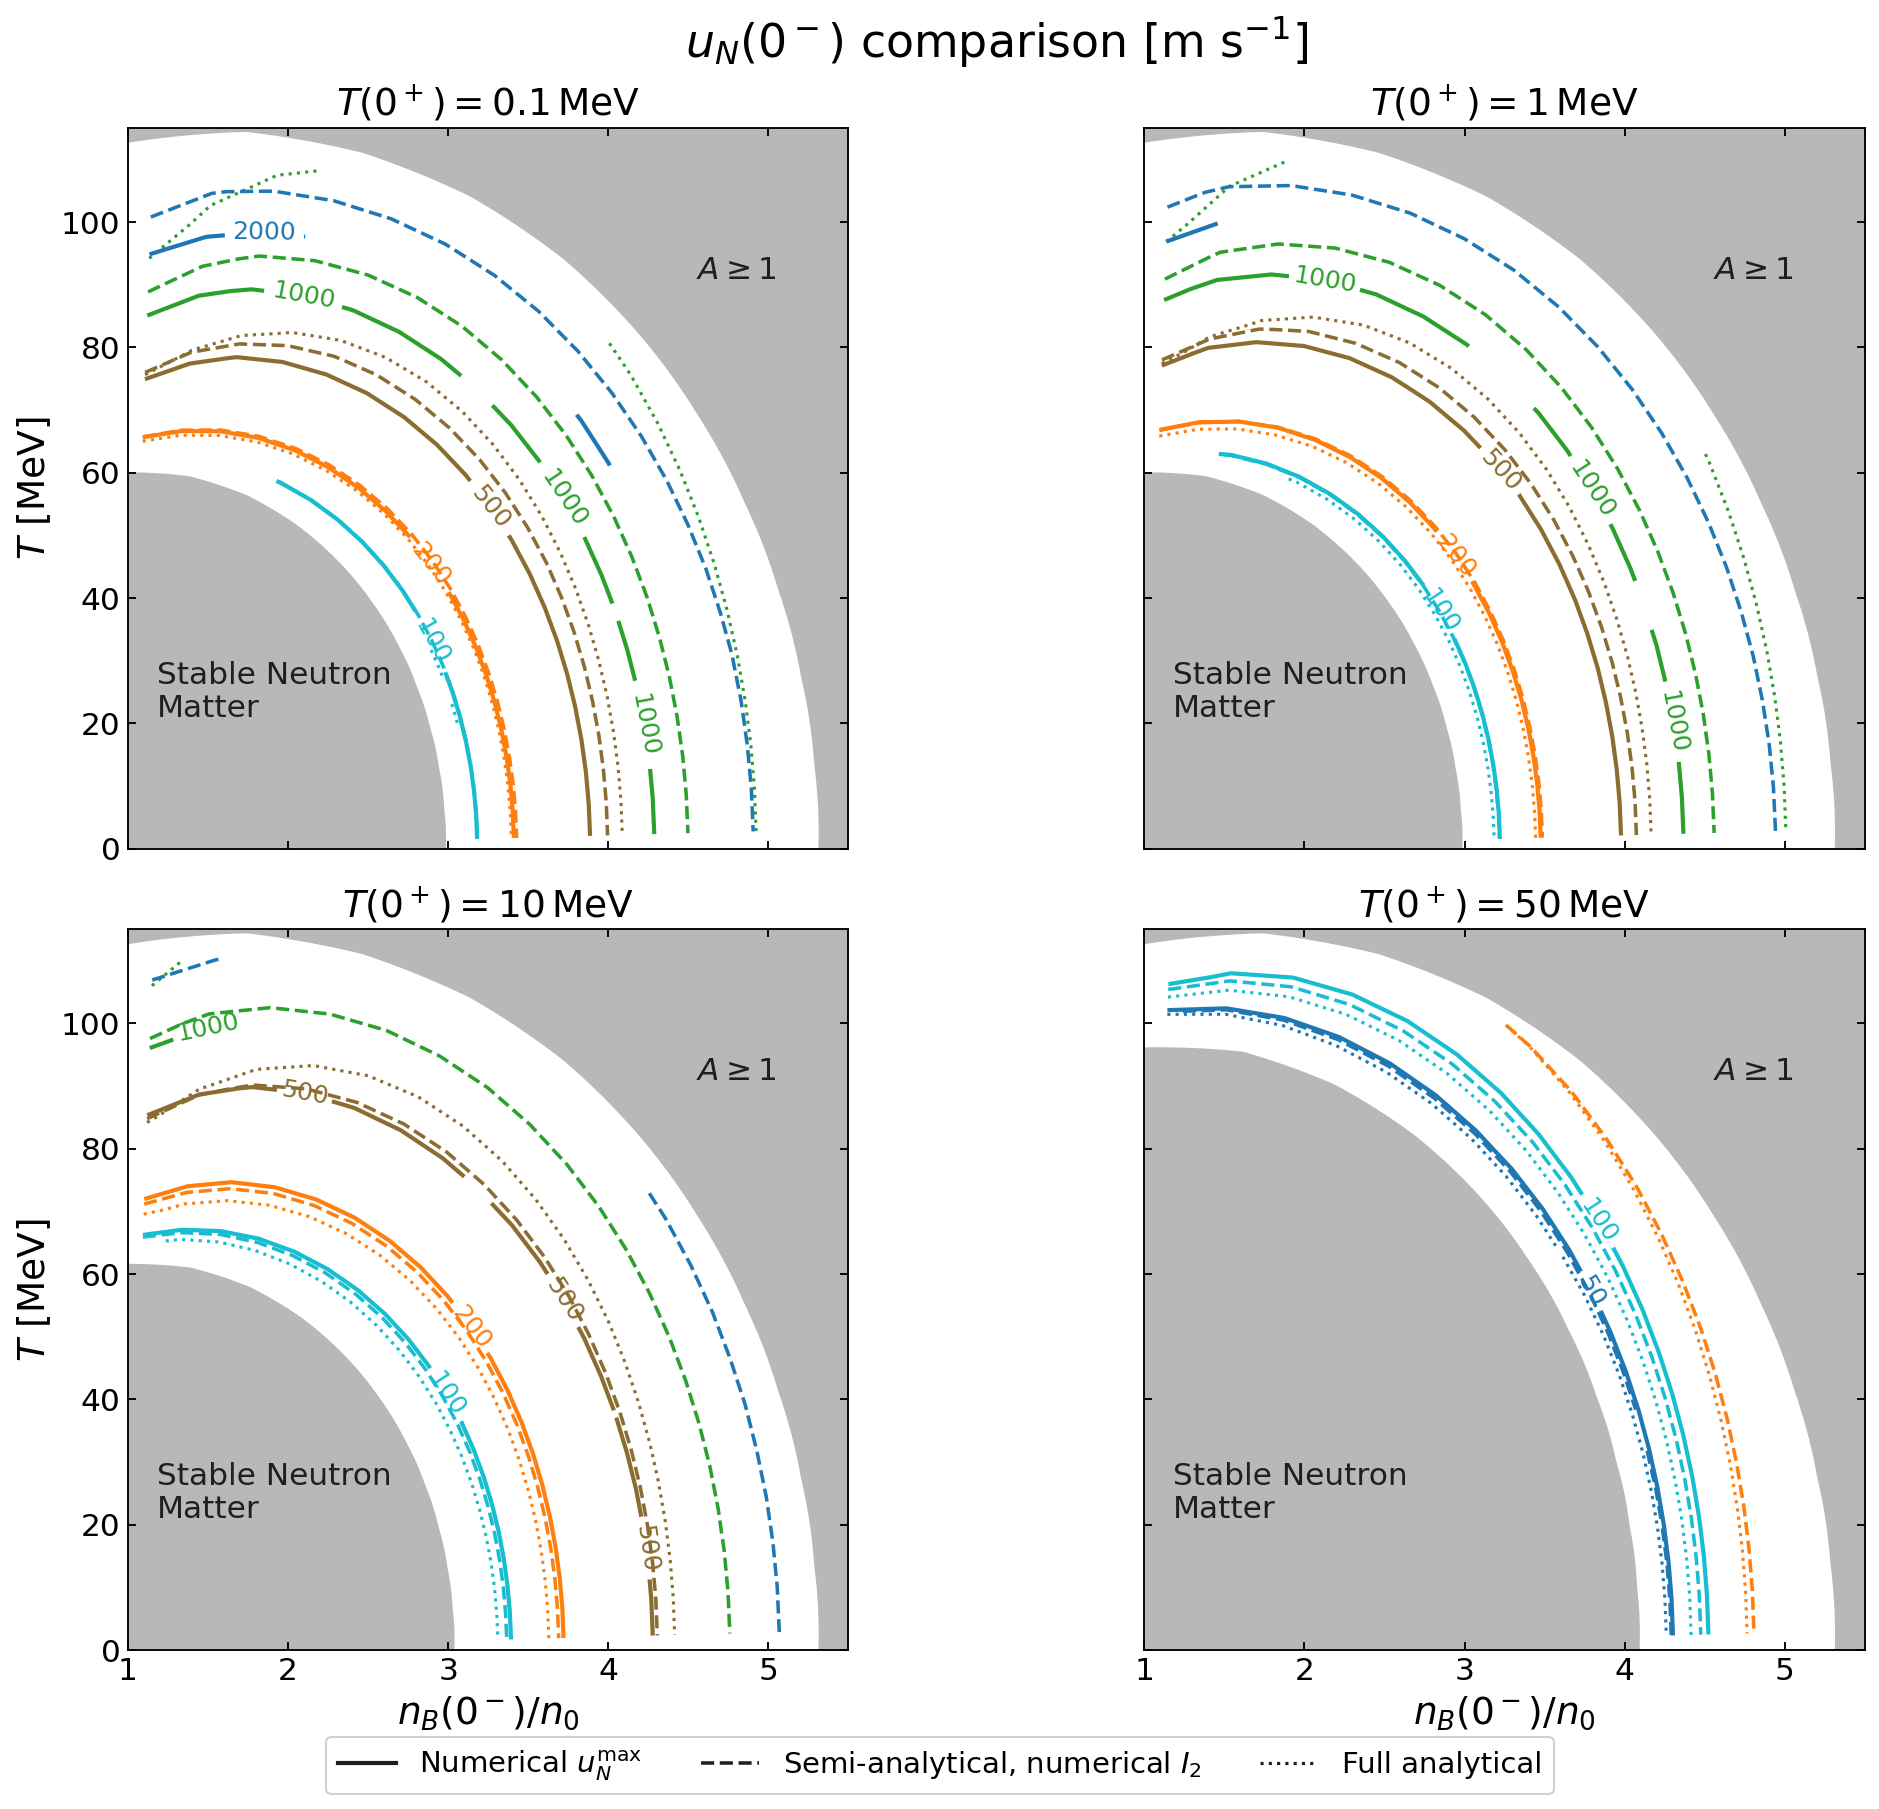

In [1]:
# Tunable plotting parameters
CONTOUR_DOMAIN_PATH = "new_paper_calculations/26-08-09/T0plus-contour-domain__run01.npy"
FULL_ANALYTIC_PATH = "new_paper_calculations/26-08-09/T0plus-full-analytic-contour__run01.npy"
SEMI_ANALYTIC_PATH = "new_paper_calculations/26-08-09/T0plus-semi-analytic-contour.npy"
FULL_NUMERICAL_PATH = "new_paper_calculations/26-08-09/T0plus-full-numerical-contour.npy"
T0PLUS_PANEL_VALUES_MEV = (0.1, 1.0, 10.0, 50.0)
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4")
NUMERICAL_LINE_STYLE = "-"
SEMI_ANALYTIC_LINE_STYLE = "--"
FULL_ANALYTIC_LINE_STYLE = ":"
NUMERICAL_LINE_WIDTH = 2.0
SEMI_ANALYTIC_LINE_WIDTH = 1.7
FULL_ANALYTIC_LINE_WIDTH = 1.5
CONTOUR_LABEL_FONT_SIZE = 12
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
BOUNDARY_INTERPOLATION_SAMPLES = 301
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
BOUNDARY_COLOR = "white"
BOUNDARY_LINE_WIDTH = 2.2
BOUNDARY_ZORDER = 1
A_REGION_TEXT = r"$A\geq1$"
A_REGION_TEXT_POSITION = (4.55, 91.0)
GAP_REGION_TEXT = "Stable Neutron\nMatter"
GAP_REGION_TEXT_POSITION = (1.18, 21.0)
REGION_TEXT_COLOR = "0.12"
REGION_TEXT_FONT_SIZE = 15
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (13.5, 12.0)
FIGURE_DPI = 150
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.0
PANEL_TITLE_FONT_SIZE = 18
PANEL_TITLE_PAD = 6
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 15
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.9
SUPTITLE = r"$u_N(0^-)$ comparison [m s$^{-1}$]"
SUPTITLE_FONT_SIZE = 22
LEGEND_LOCATION = "outside lower center"
LEGEND_COLUMNS = 3
LEGEND_FONT_SIZE = 14
LEGEND_FRAME_ALPHA = 0.92
OUTPUT_PNG = "local_analysis_results/26SU-11/T0plus-three-method-contours-26-08-09.png"
OUTPUT_PDF = "local_analysis_results/26SU-11/T0plus-three-method-contours-26-08-09.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

root = Path.cwd()
domain = np.load(root / CONTOUR_DOMAIN_PATH, allow_pickle=True).item()
full_analytic = np.load(root / FULL_ANALYTIC_PATH, allow_pickle=True).item()
semi_analytic = np.load(root / SEMI_ANALYTIC_PATH, allow_pickle=True).item()
full_numerical = np.load(root / FULL_NUMERICAL_PATH, allow_pickle=True).item()
payloads = (full_analytic, semi_analytic, full_numerical)

temperature_axis = np.asarray(domain["T_0plus_values_MeV"], dtype=float)
for payload in payloads:
    if not np.array_equal(np.asarray(payload["T_0plus_values_MeV"], dtype=float), temperature_axis):
        raise RuntimeError("Method payloads do not share the domain T(0+) axis")
temperature_indices = {float(value): index for index, value in enumerate(temperature_axis)}
missing_temperatures = [value for value in T0PLUS_PANEL_VALUES_MEV if value not in temperature_indices]
if missing_temperatures:
    raise RuntimeError(f"Missing requested T(0+) panels: {missing_temperatures}")

boundary = domain["boundary_diagnostics"]["semi_analytic"]
transform = domain["transform"]
density_origin = float(transform["density_origin_over_n0"])
density_scale = float(transform["density_scale_over_n0"])
temperature_scale = float(transform["temperature_scale_MeV"])
A_records = list(boundary["A_curve_records"])
gap_records_by_T0plus = boundary["gap_curve_records_by_T0plus"]

def boundary_curve(records):
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta_roots = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho_roots = np.asarray([row["rho"] for row in ordered], dtype=float)
    theta = np.linspace(theta_roots[0], theta_roots[-1], BOUNDARY_INTERPOLATION_SAMPLES)
    rho = np.interp(theta, theta_roots, rho_roots)
    density = density_origin + density_scale * rho * np.cos(theta)
    temperature = temperature_scale * rho * np.sin(theta)
    return density, temperature

def velocity_grid(payload, velocity_key, success_key, T_index):
    density = np.asarray(payload["nB_0minus_over_n0_grid"], dtype=float)[:, :, T_index]
    temperature = np.asarray(payload["T_0minus_MeV_grid"], dtype=float)[:, :, T_index]
    velocity = np.asarray(payload[velocity_key], dtype=float)[:, :, T_index]
    success = np.asarray(payload[success_key], dtype=bool)[:, :, T_index]
    invalid = ~success | ~np.isfinite(density) | ~np.isfinite(temperature) | ~np.isfinite(velocity)
    return density, temperature, np.ma.masked_where(invalid, velocity)

A_density, A_temperature = boundary_curve(A_records)
figure, axes = plt.subplots(
    2,
    2,
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=BACKGROUND_COLOR,
    sharex=True,
    sharey=True,
)

for axis, T0plus in zip(axes.flat, T0PLUS_PANEL_VALUES_MEV):
    T_index = temperature_indices[float(T0plus)]
    gap_density, gap_temperature = boundary_curve(gap_records_by_T0plus[float(T0plus)])
    gap_polygon_x = np.concatenate((gap_density, (X_LIMITS[0], gap_density[0])))
    gap_polygon_y = np.concatenate((gap_temperature, (Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
    axis.fill(
        gap_polygon_x, gap_polygon_y, color=EXCLUDED_REGION_COLOR,
        alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER,
    )
    A_polygon_x = np.concatenate((A_density, (X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], A_density[0])))
    A_polygon_y = np.concatenate((A_temperature, (Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
    axis.fill(
        A_polygon_x, A_polygon_y, color=EXCLUDED_REGION_COLOR,
        alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER,
    )
    axis.plot(gap_density, gap_temperature, color=BOUNDARY_COLOR, linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)
    axis.plot(A_density, A_temperature, color=BOUNDARY_COLOR, linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)

    analytic_density, analytic_temperature, analytic_velocity = velocity_grid(
        full_analytic, "u_0minus_m_s_grid", "success_grid", T_index
    )
    semi_density, semi_temperature, semi_velocity = velocity_grid(
        semi_analytic, "u_0minus_m_s_grid", "success_grid", T_index
    )
    numerical_density, numerical_temperature, numerical_velocity = velocity_grid(
        full_numerical, "numerical_downward_u_0minus_m_s_grid",
        "numerical_downward_success_grid", T_index,
    )
    axis.contour(
        analytic_density, analytic_temperature, analytic_velocity,
        levels=VELOCITY_CONTOUR_LEVELS_M_S, colors=VELOCITY_CONTOUR_COLORS,
        linestyles=FULL_ANALYTIC_LINE_STYLE, linewidths=FULL_ANALYTIC_LINE_WIDTH,
    )
    axis.contour(
        semi_density, semi_temperature, semi_velocity,
        levels=VELOCITY_CONTOUR_LEVELS_M_S, colors=VELOCITY_CONTOUR_COLORS,
        linestyles=SEMI_ANALYTIC_LINE_STYLE, linewidths=SEMI_ANALYTIC_LINE_WIDTH,
    )
    numerical_contours = axis.contour(
        numerical_density, numerical_temperature, numerical_velocity,
        levels=VELOCITY_CONTOUR_LEVELS_M_S, colors=VELOCITY_CONTOUR_COLORS,
        linestyles=NUMERICAL_LINE_STYLE, linewidths=NUMERICAL_LINE_WIDTH,
    )
    axis.clabel(
        numerical_contours, inline=CONTOUR_LABEL_INLINE, fmt=CONTOUR_LABEL_FORMAT,
        fontsize=CONTOUR_LABEL_FONT_SIZE, inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
    )
    axis.text(*A_REGION_TEXT_POSITION, A_REGION_TEXT, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.text(*GAP_REGION_TEXT_POSITION, GAP_REGION_TEXT, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.set_xlim(*X_LIMITS)
    axis.set_ylim(*Y_LIMITS_MEV)
    axis.set_xscale(X_SCALE)
    axis.set_yscale(Y_SCALE)
    axis.set_box_aspect(BOX_ASPECT)
    axis.set_title(rf"$T(0^+)={T0plus:g}\,\mathrm{{MeV}}$", fontsize=PANEL_TITLE_FONT_SIZE, pad=PANEL_TITLE_PAD)
    axis.tick_params(
        direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
        length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE,
    )
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)

for axis in axes[-1, :]:
    axis.set_xlabel(r"$n_B(0^-)/n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
for axis in axes[:, 0]:
    axis.set_ylabel(r"$T$ [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)

legend_handles = (
    Line2D((0.0,), (0.0,), color=REGION_TEXT_COLOR, linestyle=NUMERICAL_LINE_STYLE, linewidth=NUMERICAL_LINE_WIDTH, label=r"Numerical $u_N^{\max}$"),
    Line2D((0.0,), (0.0,), color=REGION_TEXT_COLOR, linestyle=SEMI_ANALYTIC_LINE_STYLE, linewidth=SEMI_ANALYTIC_LINE_WIDTH, label=r"Semi-analytical, numerical $I_2$"),
    Line2D((0.0,), (0.0,), color=REGION_TEXT_COLOR, linestyle=FULL_ANALYTIC_LINE_STYLE, linewidth=FULL_ANALYTIC_LINE_WIDTH, label="Full analytical"),
)
figure.legend(
    handles=legend_handles, loc=LEGEND_LOCATION, ncol=LEGEND_COLUMNS,
    fontsize=LEGEND_FONT_SIZE, framealpha=LEGEND_FRAME_ALPHA,
)
figure.suptitle(SUPTITLE, fontsize=SUPTITLE_FONT_SIZE)

output_png = root / OUTPUT_PNG
output_pdf = root / OUTPUT_PDF
output_png.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
figure.savefig(output_pdf, facecolor=BACKGROUND_COLOR)
print(f"Full analytical successes: {int(np.count_nonzero(full_analytic['success']))}/{full_analytic['success'].size}")
print(f"Semi-analytical successes: {int(np.count_nonzero(semi_analytic['success']))}/{semi_analytic['success'].size}")
print(
    f"Numerical successes: {int(np.count_nonzero(full_numerical['numerical_downward_success']))}/"
    f"{full_numerical['numerical_downward_success'].size}; "
    f"run_complete={full_numerical.get('run_complete')}"
)
print(f"Saved {output_png}")
plt.show()


## Stable-neutron-matter boundary at vanishing upstream temperature

This diagnostic extracts the $\theta=0$ root of $\Delta h=0$ for each saved $T(0^+)$ value. The cluster window uses $T(0^-)=0.01\,\mathrm{MeV}$ as its zero-temperature proxy, so the plot reports that value explicitly rather than silently identifying it with exact zero.

In [ ]:
# Tunable plotting parameters
INTERCEPT_DOMAIN_PATH = "new_paper_calculations/26-08-09/T0plus-contour-domain__run01.npy"
FIGURE_SIZE = (8.0, 6.2)
FIGURE_DPI = 150
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
X_SCALE = "log"
Y_SCALE = "linear"
Y_PADDING_FRACTION = 0.08
BOX_ASPECT = 0.78
INTERCEPT_LINE_COLOR = "#d62728"
INTERCEPT_LINE_STYLE = "-"
INTERCEPT_LINE_WIDTH = 2.0
INTERCEPT_MARKER_COLOR = "#d62728"
INTERCEPT_MARKER_STYLE = "o"
INTERCEPT_MARKER_SIZE = 7.0
INTERCEPT_MARKER_EDGE_COLOR = "white"
INTERCEPT_MARKER_EDGE_WIDTH = 0.8
REFERENCE_DENSITY_OVER_N0 = 3.0
REFERENCE_LINE_COLOR = "0.35"
REFERENCE_LINE_STYLE = "--"
REFERENCE_LINE_WIDTH = 1.2
GRID_COLOR = "0.82"
GRID_STYLE = ":"
GRID_LINE_WIDTH = 0.8
GRID_ALPHA = 0.8
TITLE = r"$\Delta h=0$ intercept as $T(0^-)\to0$"
TITLE_FONT_SIZE = 19
TITLE_PAD = 10
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 14
ANNOTATION_FONT_SIZE = 12
ANNOTATION_X_OFFSET_POINTS = 0
ANNOTATION_Y_OFFSET_POINTS = 9
LEGEND_LOCATION = "upper left"
LEGEND_FONT_SIZE = 12
LEGEND_FRAME_ALPHA = 0.92
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.9
OUTPUT_PNG = "local_analysis_results/26SU-11/stable-NM-zero-T0minus-intercept-vs-T0plus.png"
OUTPUT_PDF = "local_analysis_results/26SU-11/stable-NM-zero-T0minus-intercept-vs-T0plus.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
intercept_domain_path = root / INTERCEPT_DOMAIN_PATH
intercept_domain = np.load(intercept_domain_path, allow_pickle=True).item()
gap_records_by_T0plus = intercept_domain["boundary_diagnostics"]["semi_analytic"]["gap_curve_records_by_T0plus"]

intercept_rows = []
for T0plus, records in gap_records_by_T0plus.items():
    successful = [row for row in records if row.get("status") == "success"]
    if not successful:
        raise RuntimeError(f"No successful Delta h=0 roots for T(0+)={T0plus:g} MeV")
    theta_zero_row = min(successful, key=lambda row: abs(float(row["theta_rad"])))
    if not np.isclose(float(theta_zero_row["theta_rad"]), 0.0, atol=1.0e-12):
        raise RuntimeError(f"Missing theta=0 endpoint for T(0+)={T0plus:g} MeV")
    intercept_rows.append((
        float(T0plus),
        float(theta_zero_row["nB_over_n0"]),
        float(theta_zero_row["T_MeV"]),
        float(theta_zero_row["gap_MeV"]),
    ))

intercept_rows.sort(key=lambda row: row[0])
T0plus_values = np.asarray([row[0] for row in intercept_rows], dtype=float)
density_intercepts = np.asarray([row[1] for row in intercept_rows], dtype=float)
T0minus_values = np.asarray([row[2] for row in intercept_rows], dtype=float)
gap_residuals = np.asarray([row[3] for row in intercept_rows], dtype=float)

figure, axis = plt.subplots(
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    facecolor=BACKGROUND_COLOR,
    constrained_layout=True,
)
axis.plot(
    T0plus_values,
    density_intercepts,
    color=INTERCEPT_LINE_COLOR,
    linestyle=INTERCEPT_LINE_STYLE,
    linewidth=INTERCEPT_LINE_WIDTH,
    marker=INTERCEPT_MARKER_STYLE,
    markersize=INTERCEPT_MARKER_SIZE,
    markerfacecolor=INTERCEPT_MARKER_COLOR,
    markeredgecolor=INTERCEPT_MARKER_EDGE_COLOR,
    markeredgewidth=INTERCEPT_MARKER_EDGE_WIDTH,
    label=rf"$T(0^-)={T0minus_values[0]:g}\,\mathrm{{MeV}}$ roots",
)
axis.axhline(
    REFERENCE_DENSITY_OVER_N0,
    color=REFERENCE_LINE_COLOR,
    linestyle=REFERENCE_LINE_STYLE,
    linewidth=REFERENCE_LINE_WIDTH,
    label=rf"$n_B(0^-)={REFERENCE_DENSITY_OVER_N0:g}n_0$",
)
for T0plus, density in zip(T0plus_values, density_intercepts):
    axis.annotate(
        f"{density:.4f}",
        xy=(T0plus, density),
        xytext=(ANNOTATION_X_OFFSET_POINTS, ANNOTATION_Y_OFFSET_POINTS),
        textcoords="offset points",
        ha="center",
        fontsize=ANNOTATION_FONT_SIZE,
        color=INTERCEPT_LINE_COLOR,
    )
axis.set_xscale(X_SCALE)
axis.set_yscale(Y_SCALE)
density_plot_min = min(float(np.min(density_intercepts)), REFERENCE_DENSITY_OVER_N0)
density_plot_max = max(float(np.max(density_intercepts)), REFERENCE_DENSITY_OVER_N0)
density_plot_span = density_plot_max - density_plot_min
axis.set_ylim(
    density_plot_min - Y_PADDING_FRACTION * density_plot_span,
    density_plot_max + Y_PADDING_FRACTION * density_plot_span,
)
axis.set_box_aspect(BOX_ASPECT)
axis.set_xlabel(r"$T(0^+)$ [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(r"$n_{B,\,\Delta h=0}(0^-)/n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
axis.grid(True, which="both", color=GRID_COLOR, linestyle=GRID_STYLE, linewidth=GRID_LINE_WIDTH, alpha=GRID_ALPHA)
axis.tick_params(
    direction=TICK_DIRECTION,
    top=TICKS_TOP,
    right=TICKS_RIGHT,
    length=TICK_LENGTH,
    width=TICK_WIDTH,
    labelsize=TICK_LABEL_FONT_SIZE,
)
for spine in axis.spines.values():
    spine.set_linewidth(SPINE_LINE_WIDTH)
axis.legend(loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE, framealpha=LEGEND_FRAME_ALPHA)

output_png = root / OUTPUT_PNG
output_pdf = root / OUTPUT_PDF
output_png.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
figure.savefig(output_pdf, facecolor=BACKGROUND_COLOR)

print("T(0+) [MeV]   T(0-) used [MeV]   nB intercept / n0   Delta h residual [MeV]")
for T0plus, density, T0minus, residual in intercept_rows:
    print(f"{T0plus:11.4g}   {T0minus:16.4g}   {density:17.9f}   {residual:22.3e}")
print(f"Saved {output_png}")
plt.show()


T(0+)=0.01 MeV: accepted 260/600
T(0+)=0.1 MeV: accepted 149/200
T(0+)=1 MeV: accepted 149/200
T(0+)=5 MeV: accepted 516/600
T(0+)=10 MeV: accepted 150/200
T(0+)=50 MeV: accepted 137/200
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-11/numerical-T0plus-overlaid-contours.png


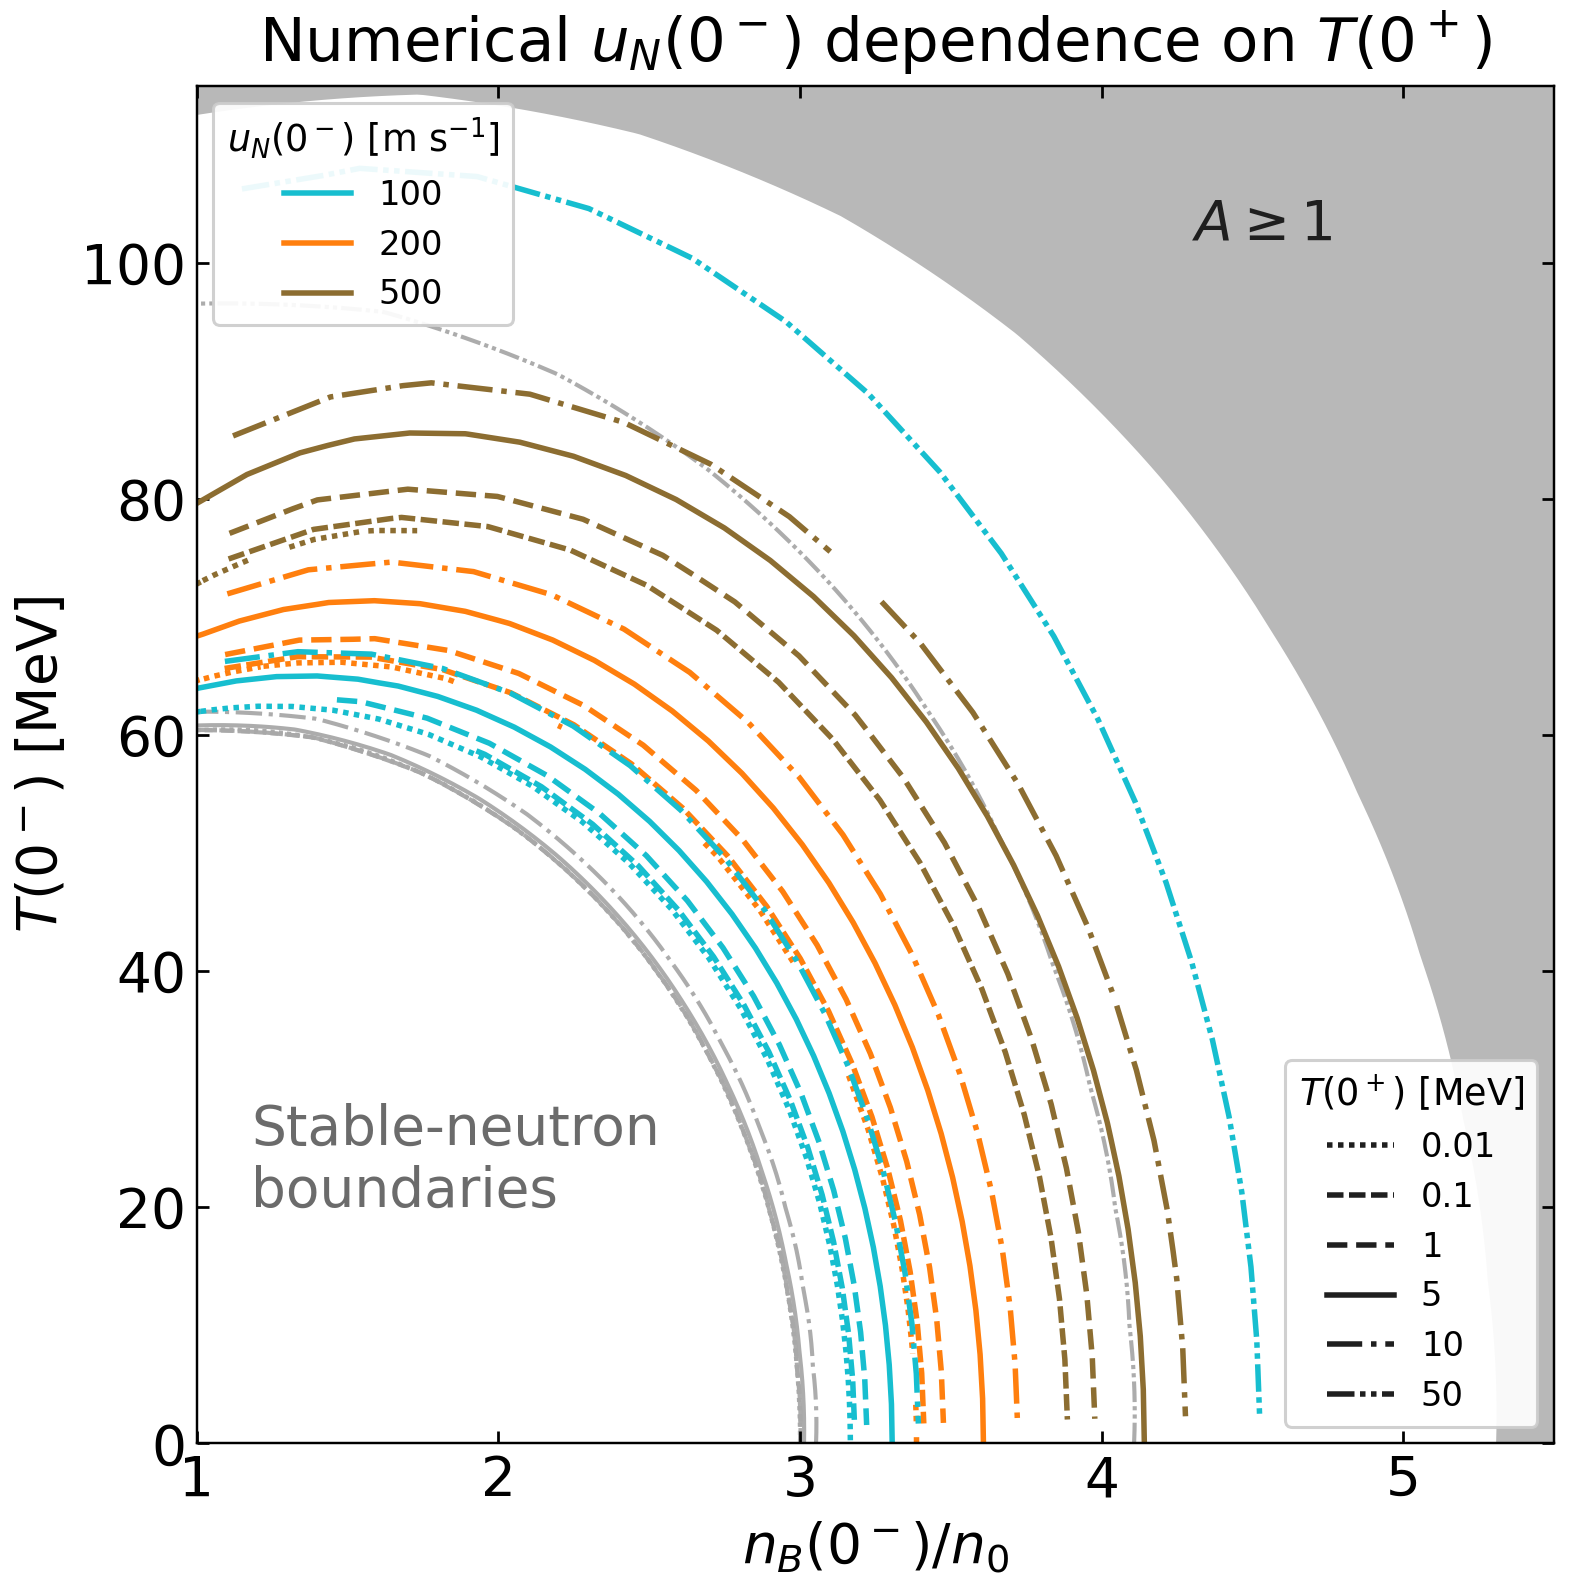

In [ ]:
# Tunable plotting parameters
NUMERICAL_T0PLUS_CASES = (
    {
        "T_0plus_MeV": 0.01,
        "numerical_path": "new_paper_calculations/26-08-04/uNmax-T-nB-ray-grid-TQstar-0p01-numerical-I2-seeded.npy",
        "schema": "legacy_T_nB_ray_grid",
        "line_style": (0, (1, 1)),
    },
    {
        "T_0plus_MeV": 0.1,
        "domain_path": "new_paper_calculations/26-08-09/T0plus-contour-domain__run01.npy",
        "numerical_path": "new_paper_calculations/26-08-09/T0plus-full-numerical-contour.npy",
        "velocity_key": "numerical_downward_u_0minus_m_s_grid",
        "success_key": "numerical_downward_success_grid",
        "line_style": (0, (3, 1)),
    },
    {
        "T_0plus_MeV": 1.0,
        "domain_path": "new_paper_calculations/26-08-09/T0plus-contour-domain__run01.npy",
        "numerical_path": "new_paper_calculations/26-08-09/T0plus-full-numerical-contour.npy",
        "velocity_key": "numerical_downward_u_0minus_m_s_grid",
        "success_key": "numerical_downward_success_grid",
        "line_style": "--",
    },
    {
        "T_0plus_MeV": 5.0,
        "domain_path": "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-domain.npy",
        "numerical_path": "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-uNmax-radial-continuation-T0minus0-local-patched.npy",
        "velocity_key": "numerical_outward_u_0minus_m_s_grid",
        "success_key": "numerical_outward_success_grid",
        "line_style": "-",
    },
    {
        "T_0plus_MeV": 10.0,
        "domain_path": "new_paper_calculations/26-08-09/T0plus-contour-domain__run01.npy",
        "numerical_path": "new_paper_calculations/26-08-09/T0plus-full-numerical-contour.npy",
        "velocity_key": "numerical_downward_u_0minus_m_s_grid",
        "success_key": "numerical_downward_success_grid",
        "line_style": "-.",
    },
    {
        "T_0plus_MeV": 50.0,
        "domain_path": "new_paper_calculations/26-08-09/T0plus-contour-domain__run01.npy",
        "numerical_path": "new_paper_calculations/26-08-09/T0plus-full-numerical-contour.npy",
        "velocity_key": "numerical_downward_u_0minus_m_s_grid",
        "success_key": "numerical_downward_success_grid",
        "line_style": (0, (5, 1, 1, 1, 1, 1)),
    },
)
VELOCITY_CONTOUR_LEVELS_M_S = (100.0, 200.0, 500.0)
VELOCITY_CONTOUR_COLORS = ("#17becf", "#ff7f0e", "#8c6d31")
NUMERICAL_LINE_WIDTH = 1.8
BOUNDARY_INTERPOLATION_SAMPLES = 401
A_EXCLUDED_REGION_COLOR = "0.72"
A_EXCLUDED_REGION_ALPHA = 1.0
A_EXCLUDED_REGION_ZORDER = 0
A_BOUNDARY_COLOR = "white"
A_BOUNDARY_LINE_WIDTH = 1.8
A_BOUNDARY_ZORDER = 1
A_REGION_TEXT = r"$A\geq1$"
A_REGION_TEXT_POSITION = (4.3, 102.0)
A_REGION_TEXT_COLOR = "0.12"
A_REGION_TEXT_FONT_SIZE = 18
A_REGION_TEXT_ZORDER = 5
STABLE_BOUNDARY_COLOR = "0.66"
STABLE_BOUNDARY_LINE_WIDTH = 1.35
STABLE_BOUNDARY_ALPHA = 0.95
STABLE_BOUNDARY_ZORDER = 1
STABLE_BOUNDARY_TEXT = "Stable-neutron\nboundaries"
STABLE_BOUNDARY_TEXT_POSITION = (1.18, 20.0)
STABLE_BOUNDARY_TEXT_COLOR = "0.42"
STABLE_BOUNDARY_TEXT_FONT_SIZE = 18
STABLE_BOUNDARY_TEXT_ZORDER = 4
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.0
TITLE = r"Numerical $u_N(0^-)$ dependence on $T(0^+)$"
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
VELOCITY_LEGEND_TITLE = r"$u_N(0^-)$ [m s$^{-1}$]"
VELOCITY_LEGEND_LOCATION = "upper left"
TEMPERATURE_LEGEND_TITLE = r"$T(0^+)$ [MeV]"
TEMPERATURE_LEGEND_LOCATION = "lower right"
LEGEND_FONT_SIZE = 11
LEGEND_TITLE_FONT_SIZE = 12
LEGEND_FRAME_ALPHA = 0.92
LEGEND_LINE_WIDTH = 1.8
OUTPUT_PNG = "local_analysis_results/26SU-11/numerical-T0plus-overlaid-contours.png"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/Numerical-T0plus-comparison.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

root = Path.cwd()
payload_cache = {}

def load_payload(relative_path):
    if relative_path not in payload_cache:
        payload_cache[relative_path] = np.load(root / relative_path, allow_pickle=True).item()
    return payload_cache[relative_path]

def temperature_index(payload, target_temperature):
    values = np.asarray(payload["T_0plus_values_MeV"], dtype=float)
    matches = np.flatnonzero(np.isclose(values, target_temperature))
    if matches.size != 1:
        raise RuntimeError(
            f"Expected one T(0+)={target_temperature:g} MeV entry, found {values}"
        )
    return int(matches[0])

def records_at_temperature(records_by_temperature, target_temperature):
    for saved_temperature, records in records_by_temperature.items():
        if np.isclose(float(saved_temperature), target_temperature):
            return records
    raise RuntimeError(f"Missing boundary for T(0+)={target_temperature:g} MeV")

def boundary_curve(domain, records):
    transform = domain["transform"]
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta_roots = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho_roots = np.asarray([row["rho"] for row in ordered], dtype=float)
    theta = np.linspace(theta_roots[0], theta_roots[-1], BOUNDARY_INTERPOLATION_SAMPLES)
    rho = np.interp(theta, theta_roots, rho_roots)
    density = (
        float(transform["density_origin_over_n0"])
        + float(transform["density_scale_over_n0"]) * rho * np.cos(theta)
    )
    temperature = float(transform["temperature_scale_MeV"]) * rho * np.sin(theta)
    return density, temperature

def numerical_grid(case, numerical):
    if case.get("schema") == "legacy_T_nB_ray_grid":
        density = np.asarray(numerical["nB_grid_over_n0"], dtype=float)
        temperature = np.asarray(numerical["temperature_grid_MeV"], dtype=float)
        velocity = np.asarray(numerical["velocity_grid_m_s"], dtype=float)
        success = np.asarray(numerical["status_grid"]) == 0
    else:
        T_index = temperature_index(numerical, case["T_0plus_MeV"])
        density = np.asarray(numerical["nB_0minus_over_n0_grid"], dtype=float)[:, :, T_index]
        temperature = np.asarray(numerical["T_0minus_MeV_grid"], dtype=float)[:, :, T_index]
        velocity = np.asarray(numerical[case["velocity_key"]], dtype=float)[:, :, T_index]
        success = np.asarray(numerical[case["success_key"]], dtype=bool)[:, :, T_index]
    invalid = ~success | ~np.isfinite(density) | ~np.isfinite(temperature) | ~np.isfinite(velocity)
    return density, temperature, np.ma.masked_where(invalid, velocity), success

def stable_boundary_curve(case, domain, numerical):
    if case.get("schema") == "legacy_T_nB_ray_grid":
        return (
            np.asarray(numerical["gap_boundary_nB_over_n0"], dtype=float),
            np.asarray(numerical["gap_boundary_temperature_MeV"], dtype=float),
        )
    boundary = domain["boundary_diagnostics"]["semi_analytic"]
    inner_records = records_at_temperature(
        boundary["gap_curve_records_by_T0plus"], case["T_0plus_MeV"]
    )
    return boundary_curve(domain, inner_records)

figure, axis = plt.subplots(
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=BACKGROUND_COLOR,
)

reference_domain = load_payload(NUMERICAL_T0PLUS_CASES[2]["domain_path"])
reference_boundary = reference_domain["boundary_diagnostics"]["semi_analytic"]
A_density, A_temperature = boundary_curve(
    reference_domain, reference_boundary["A_curve_records"]
)
A_polygon_x = np.concatenate(
    (A_density, (X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], A_density[0]))
)
A_polygon_y = np.concatenate(
    (A_temperature, (Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]))
)
axis.fill(
    A_polygon_x,
    A_polygon_y,
    color=A_EXCLUDED_REGION_COLOR,
    alpha=A_EXCLUDED_REGION_ALPHA,
    zorder=A_EXCLUDED_REGION_ZORDER,
)
axis.plot(
    A_density,
    A_temperature,
    color=A_BOUNDARY_COLOR,
    linewidth=A_BOUNDARY_LINE_WIDTH,
    zorder=A_BOUNDARY_ZORDER,
)

case_summaries = []
for case in NUMERICAL_T0PLUS_CASES:
    T_0plus = float(case["T_0plus_MeV"])
    numerical = load_payload(case["numerical_path"])
    domain = (
        reference_domain
        if case.get("schema") == "legacy_T_nB_ray_grid"
        else load_payload(case["domain_path"])
    )
    inner_density, inner_temperature = stable_boundary_curve(case, domain, numerical)
    axis.plot(
        inner_density,
        inner_temperature,
        color=STABLE_BOUNDARY_COLOR,
        linestyle=case["line_style"],
        linewidth=STABLE_BOUNDARY_LINE_WIDTH,
        alpha=STABLE_BOUNDARY_ALPHA,
        zorder=STABLE_BOUNDARY_ZORDER,
    )
    density, temperature, velocity, success = numerical_grid(case, numerical)
    axis.contour(
        density,
        temperature,
        velocity,
        levels=VELOCITY_CONTOUR_LEVELS_M_S,
        colors=VELOCITY_CONTOUR_COLORS,
        linestyles=[case["line_style"]] * len(VELOCITY_CONTOUR_LEVELS_M_S),
        linewidths=NUMERICAL_LINE_WIDTH,
    )
    case_summaries.append(
        (T_0plus, int(np.count_nonzero(success)), int(success.size))
    )

axis.text(
    *A_REGION_TEXT_POSITION,
    A_REGION_TEXT,
    color=A_REGION_TEXT_COLOR,
    fontsize=A_REGION_TEXT_FONT_SIZE,
    zorder=A_REGION_TEXT_ZORDER,
)
axis.text(
    *STABLE_BOUNDARY_TEXT_POSITION,
    STABLE_BOUNDARY_TEXT,
    color=STABLE_BOUNDARY_TEXT_COLOR,
    fontsize=STABLE_BOUNDARY_TEXT_FONT_SIZE,
    zorder=STABLE_BOUNDARY_TEXT_ZORDER,
)
axis.set_xlim(*X_LIMITS)
axis.set_ylim(*Y_LIMITS_MEV)
axis.set_xscale(X_SCALE)
axis.set_yscale(Y_SCALE)
axis.set_box_aspect(BOX_ASPECT)
axis.set_xlabel(r"$n_B(0^-)/n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(r"$T(0^-)$ [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
axis.tick_params(
    direction=TICK_DIRECTION,
    top=TICKS_TOP,
    right=TICKS_RIGHT,
    length=TICK_LENGTH,
    width=TICK_WIDTH,
    labelsize=TICK_LABEL_FONT_SIZE,
)
for spine in axis.spines.values():
    spine.set_linewidth(SPINE_LINE_WIDTH)

velocity_handles = tuple(
    Line2D(
        (0.0,),
        (0.0,),
        color=color,
        linestyle="-",
        linewidth=LEGEND_LINE_WIDTH,
        label=f"{level:g}",
    )
    for level, color in zip(VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS)
)
velocity_legend = axis.legend(
    handles=velocity_handles,
    title=VELOCITY_LEGEND_TITLE,
    loc=VELOCITY_LEGEND_LOCATION,
    fontsize=LEGEND_FONT_SIZE,
    title_fontsize=LEGEND_TITLE_FONT_SIZE,
    framealpha=LEGEND_FRAME_ALPHA,
)
axis.add_artist(velocity_legend)
temperature_handles = tuple(
    Line2D(
        (0.0,),
        (0.0,),
        color=A_REGION_TEXT_COLOR,
        linestyle=case["line_style"],
        linewidth=LEGEND_LINE_WIDTH,
        label=f"{case['T_0plus_MeV']:g}",
    )
    for case in NUMERICAL_T0PLUS_CASES
)
axis.legend(
    handles=temperature_handles,
    title=TEMPERATURE_LEGEND_TITLE,
    loc=TEMPERATURE_LEGEND_LOCATION,
    fontsize=LEGEND_FONT_SIZE,
    title_fontsize=LEGEND_TITLE_FONT_SIZE,
    framealpha=LEGEND_FRAME_ALPHA,
)

output_png = root / OUTPUT_PNG
output_pdf = root / OUTPUT_PDF
output_png.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
figure.savefig(output_pdf, facecolor=BACKGROUND_COLOR)
for T_0plus, accepted, total in case_summaries:
    print(f"T(0+)={T_0plus:g} MeV: accepted {accepted}/{total}")
print(f"Saved {output_png}")
plt.show()


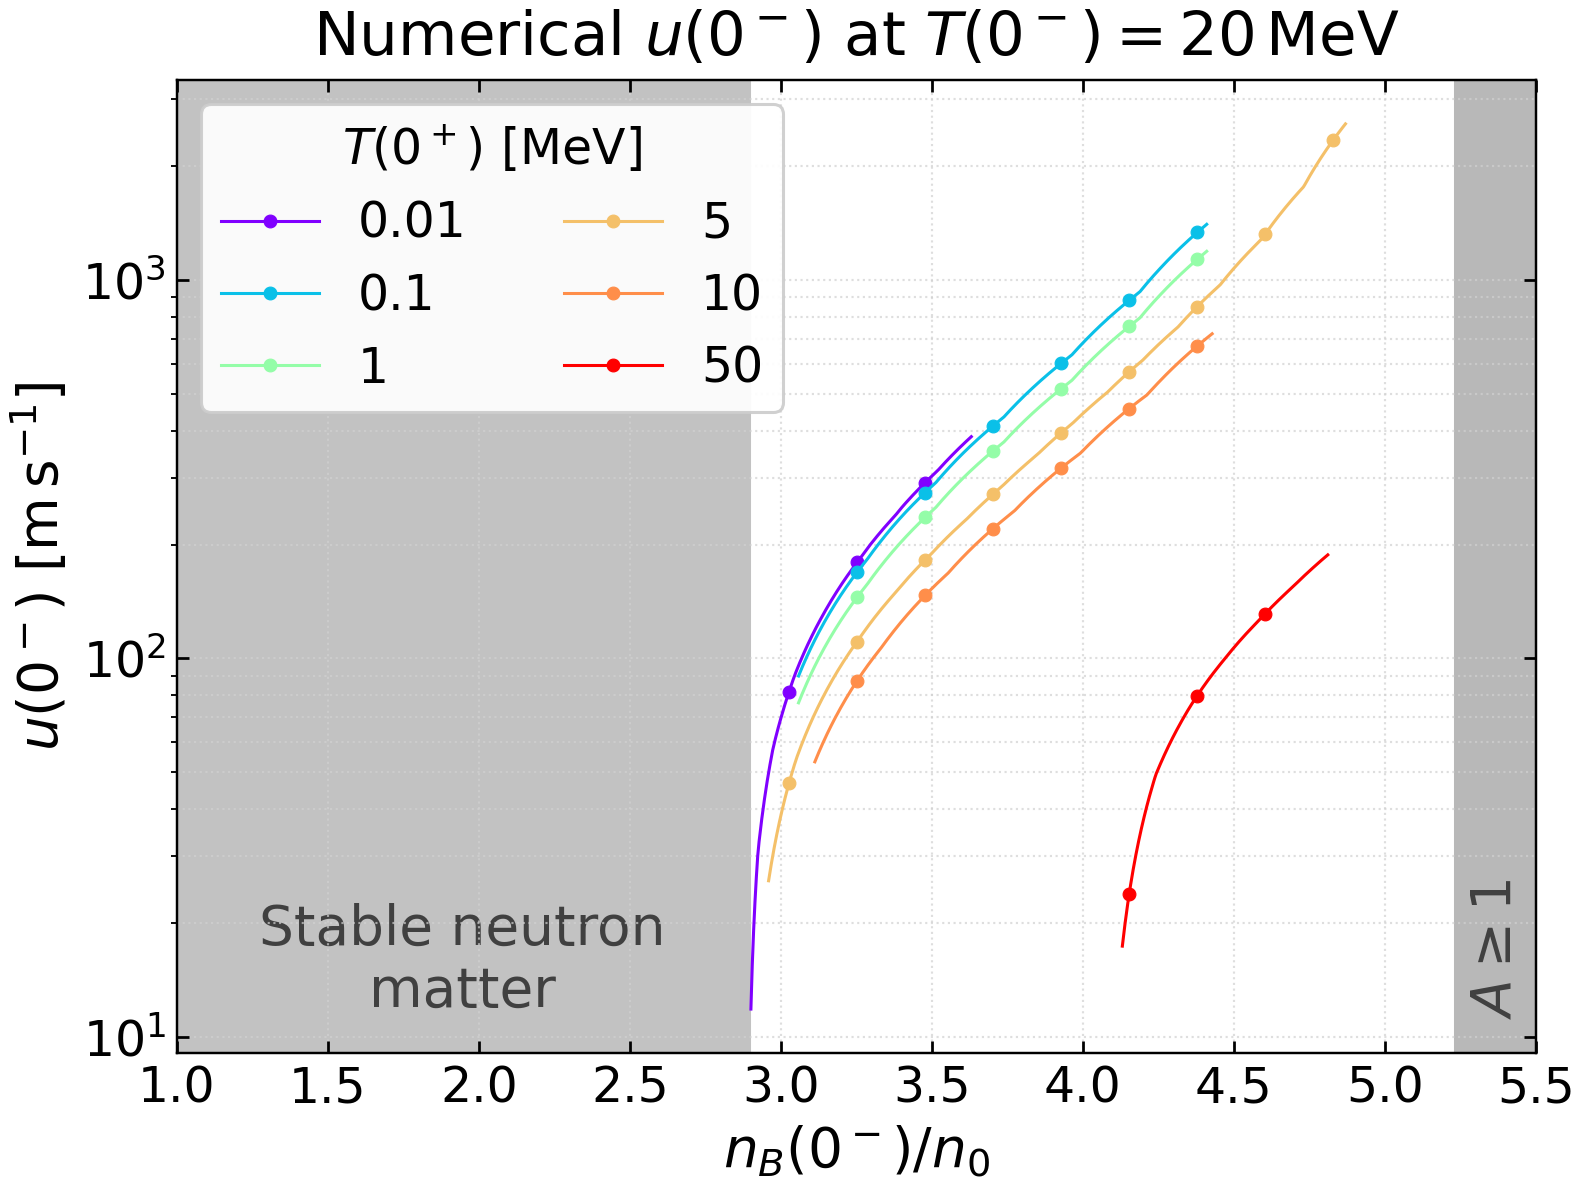

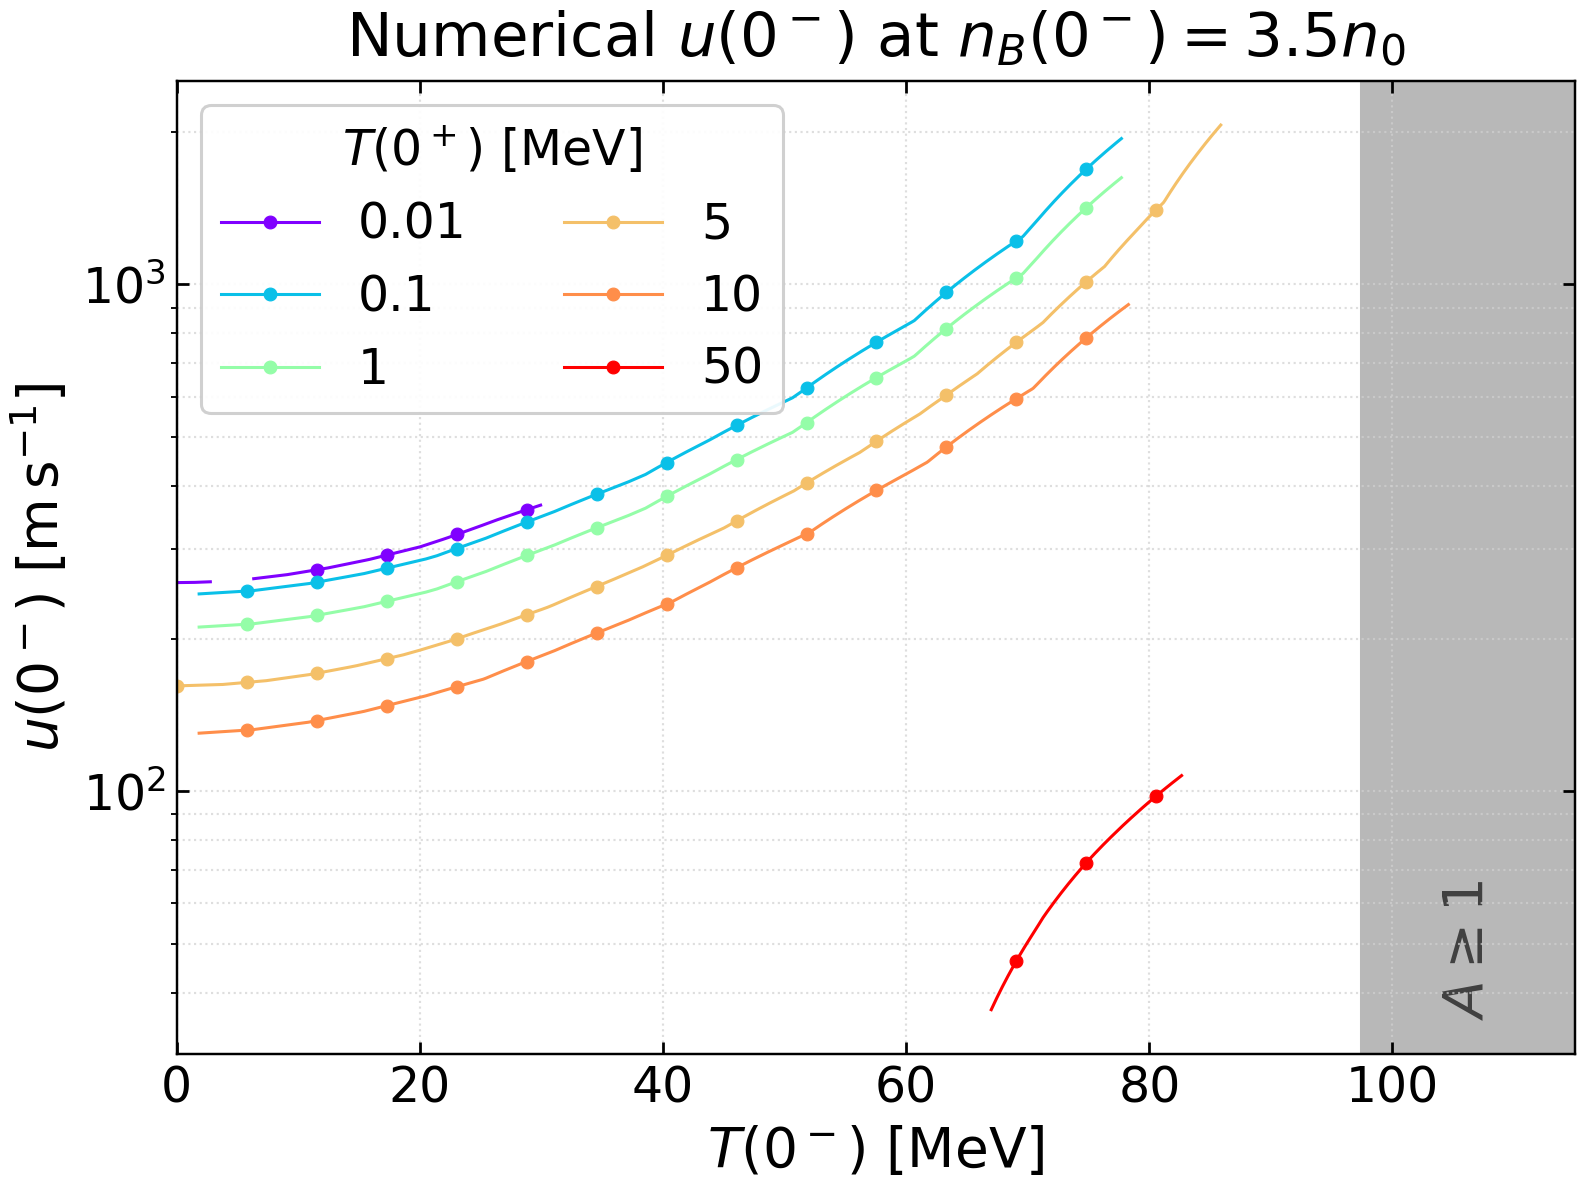

In [ ]:
# Tunable plotting parameters
NUMERICAL_T0PLUS_SLICE_CASES = (
    {
        "T_0plus_MeV": 0.01,
        "numerical_path": "new_paper_calculations/26-08-04/uNmax-T-nB-ray-grid-TQstar-0p01-numerical-I2-seeded.npy",
        "schema": "legacy_T_nB_ray_grid",
    },
    {
        "T_0plus_MeV": 0.1,
        "domain_path": "new_paper_calculations/26-08-09/T0plus-contour-domain__run01.npy",
        "numerical_path": "new_paper_calculations/26-08-09/T0plus-full-numerical-contour.npy",
        "velocity_key": "numerical_downward_u_0minus_m_s_grid",
        "success_key": "numerical_downward_success_grid",
    },
    {
        "T_0plus_MeV": 1.0,
        "domain_path": "new_paper_calculations/26-08-09/T0plus-contour-domain__run01.npy",
        "numerical_path": "new_paper_calculations/26-08-09/T0plus-full-numerical-contour.npy",
        "velocity_key": "numerical_downward_u_0minus_m_s_grid",
        "success_key": "numerical_downward_success_grid",
    },
    {
        "T_0plus_MeV": 5.0,
        "domain_path": "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-domain.npy",
        "numerical_path": "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-uNmax-radial-continuation-T0minus0-local-patched.npy",
        "velocity_key": "numerical_outward_u_0minus_m_s_grid",
        "success_key": "numerical_outward_success_grid",
    },
    {
        "T_0plus_MeV": 10.0,
        "domain_path": "new_paper_calculations/26-08-09/T0plus-contour-domain__run01.npy",
        "numerical_path": "new_paper_calculations/26-08-09/T0plus-full-numerical-contour.npy",
        "velocity_key": "numerical_downward_u_0minus_m_s_grid",
        "success_key": "numerical_downward_success_grid",
    },
    {
        "T_0plus_MeV": 50.0,
        "domain_path": "new_paper_calculations/26-08-09/T0plus-contour-domain__run01.npy",
        "numerical_path": "new_paper_calculations/26-08-09/T0plus-full-numerical-contour.npy",
        "velocity_key": "numerical_downward_u_0minus_m_s_grid",
        "success_key": "numerical_downward_success_grid",
    },
)
T0PLUS_COLORMAP_NAME = "rainbow"
T0PLUS_COLOR_LIMITS_MEV = (0.01, 50.0)
LEGEND_TITLE = r"$T(0^+)$ [MeV]"
LEGEND_LOCATION = "best"
LEGEND_FONT_SIZE = 16
LEGEND_TITLE_FONT_SIZE = 16
LEGEND_COLUMNS = 2
LEGEND_FRAME_ALPHA = 0.92
FIXED_T0MINUS_MEV = 20.0
FIXED_NB_0MINUS_OVER_N0 = 3.5
DENSITY_SLICE_X_LIMITS = (1.0, 5.5)
TEMPERATURE_SLICE_X_LIMITS_MEV = (0.0, 115.0)
VELOCITY_Y_LIMITS_M_S = None
SLICE_SAMPLE_COUNT = 1000
TRIANGLE_AREA_TOLERANCE = 1.0e-12
MINIMUM_PLOTTED_VELOCITY_M_S = 1.0e-12
STABLE_SHADE_COLOR = "0.76"
A_SHADE_COLOR = "0.72"
SHADE_ALPHA = 1.0
SHADE_ZORDER = 0
STABLE_SHADE_TEXT = "Stable neutron\nmatter"
A_SHADE_TEXT = r"$A\geq1$"
SHADE_TEXT_Y_FRACTION = 0.035
SHADE_TEXT_COLOR = "0.25"
SHADE_TEXT_FONT_SIZE = 18
A_SHADE_TEXT_ROTATION = 90
LINE_STYLE = "-"
LINE_WIDTH = 1.0
MARKER_STYLE = "o"
MARKER_SIZE = 4.2
MARKER_EVERY = 50
MARKER_EDGE_WIDTH = 0.35
FIGURE_SIZE = (7.2, 5.4)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
Y_SCALE = "log"
DENSITY_SLICE_TITLE = rf"Numerical $u(0^-)$ at $T(0^-)={FIXED_T0MINUS_MEV:g}\,\mathrm{{MeV}}$"
TEMPERATURE_SLICE_TITLE = rf"Numerical $u(0^-)$ at $n_B(0^-)={FIXED_NB_0MINUS_OVER_N0:g}n_0$"
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 16
GRID_ENABLED = True
GRID_WHICH = "both"
GRID_COLOR = "0.82"
GRID_LINE_STYLE = ":"
GRID_LINE_WIDTH = 0.7
GRID_ALPHA = 0.7
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
DENSITY_SLICE_OUTPUT_PNG = "local_analysis_results/26SU-11/Numerical-T0plus-compare-fixT.png"
DENSITY_SLICE_OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/Numerical-T0plus-compare-fixT.pdf"
TEMPERATURE_SLICE_OUTPUT_PNG = "local_analysis_results/26SU-11/Numerical-T0plus-compare-fixnB.png"
TEMPERATURE_SLICE_OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/Numerical-T0plus-compare-fixnB.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
from matplotlib.colors import LogNorm

root = Path.cwd()
payload_cache = {}
T0PLUS_COLORMAP = plt.get_cmap(T0PLUS_COLORMAP_NAME)
T0PLUS_COLOR_NORM = LogNorm(*T0PLUS_COLOR_LIMITS_MEV)

def load_payload(relative_path):
    if relative_path not in payload_cache:
        payload_cache[relative_path] = np.load(root / relative_path, allow_pickle=True).item()
    return payload_cache[relative_path]

def temperature_index(payload, target_temperature):
    values = np.asarray(payload["T_0plus_values_MeV"], dtype=float)
    matches = np.flatnonzero(np.isclose(values, target_temperature))
    if matches.size != 1:
        raise RuntimeError(
            f"Expected one T(0+)={target_temperature:g} MeV entry, found {values}"
        )
    return int(matches[0])

def numerical_grid(case):
    numerical = load_payload(case["numerical_path"])
    if case.get("schema") == "legacy_T_nB_ray_grid":
        density = np.asarray(numerical["nB_grid_over_n0"], dtype=float)
        temperature = np.asarray(numerical["temperature_grid_MeV"], dtype=float)
        velocity = np.asarray(numerical["velocity_grid_m_s"], dtype=float)
        success = np.asarray(numerical["status_grid"]) == 0
    else:
        T_index = temperature_index(numerical, case["T_0plus_MeV"])
        density = np.asarray(numerical["nB_0minus_over_n0_grid"], dtype=float)[:, :, T_index]
        temperature = np.asarray(numerical["T_0minus_MeV_grid"], dtype=float)[:, :, T_index]
        velocity = np.asarray(numerical[case["velocity_key"]], dtype=float)[:, :, T_index]
        success = np.asarray(numerical[case["success_key"]], dtype=bool)[:, :, T_index]
    return density, temperature, velocity, success

def records_at_temperature(records_by_temperature, target_temperature):
    for saved_temperature, records in records_by_temperature.items():
        if np.isclose(float(saved_temperature), target_temperature):
            return records
    raise RuntimeError(f"Missing boundary for T(0+)={target_temperature:g} MeV")

def transformed_boundary_curve(domain, records):
    transform = domain["transform"]
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho = np.asarray([row["rho"] for row in ordered], dtype=float)
    density = (
        float(transform["density_origin_over_n0"])
        + float(transform["density_scale_over_n0"]) * rho * np.cos(theta)
    )
    temperature = float(transform["temperature_scale_MeV"]) * rho * np.sin(theta)
    return density, temperature

def stable_boundary_curve(case):
    if case.get("schema") == "legacy_T_nB_ray_grid":
        numerical = load_payload(case["numerical_path"])
        return (
            np.asarray(numerical["gap_boundary_nB_over_n0"], dtype=float),
            np.asarray(numerical["gap_boundary_temperature_MeV"], dtype=float),
        )
    domain = load_payload(case["domain_path"])
    boundary = domain["boundary_diagnostics"]["semi_analytic"]
    records = records_at_temperature(
        boundary["gap_curve_records_by_T0plus"], case["T_0plus_MeV"]
    )
    return transformed_boundary_curve(domain, records)

def curve_intersection(independent_values, target_value, dependent_values):
    independent = np.asarray(independent_values, dtype=float)
    dependent = np.asarray(dependent_values, dtype=float)
    finite = np.isfinite(independent) & np.isfinite(dependent)
    independent = independent[finite]
    dependent = dependent[finite]
    order = np.argsort(independent)
    independent = independent[order]
    dependent = dependent[order]
    if target_value < independent[0] or target_value > independent[-1]:
        return None
    return float(np.interp(target_value, independent, dependent))

def stable_density_threshold_at_temperature(density, temperature):
    threshold = curve_intersection(temperature, FIXED_T0MINUS_MEV, density)
    if threshold is not None:
        return threshold
    if FIXED_T0MINUS_MEV > np.nanmax(temperature):
        return DENSITY_SLICE_X_LIMITS[0]
    return float(np.nanmax(density))

def stable_temperature_threshold_at_density(density, temperature):
    threshold = curve_intersection(density, FIXED_NB_0MINUS_OVER_N0, temperature)
    if threshold is not None:
        return threshold
    if FIXED_NB_0MINUS_OVER_N0 > np.nanmax(density):
        return TEMPERATURE_SLICE_X_LIMITS_MEV[0]
    return float(np.nanmax(temperature))

def structured_interpolator(density, temperature, velocity, success):
    valid = (
        success
        & np.isfinite(density)
        & np.isfinite(temperature)
        & np.isfinite(velocity)
        & (velocity > MINIMUM_PLOTTED_VELOCITY_M_S)
    )
    row_count, column_count = density.shape
    triangles = []
    flat_density = density.ravel()
    flat_temperature = temperature.ravel()
    flat_velocity = velocity.ravel()
    flat_valid = valid.ravel()

    def append_triangle(indices):
        if not np.all(flat_valid[np.asarray(indices, dtype=int)]):
            return
        x0, x1, x2 = flat_density[list(indices)]
        y0, y1, y2 = flat_temperature[list(indices)]
        twice_area = abs((x1 - x0) * (y2 - y0) - (x2 - x0) * (y1 - y0))
        if twice_area > TRIANGLE_AREA_TOLERANCE:
            triangles.append(indices)

    for row in range(row_count - 1):
        for column in range(column_count - 1):
            lower_left = row * column_count + column
            upper_left = (row + 1) * column_count + column
            lower_right = lower_left + 1
            upper_right = upper_left + 1
            append_triangle((lower_left, upper_left, upper_right))
            append_triangle((lower_left, upper_right, lower_right))

    if not triangles:
        return None, 0
    triangulation = mtri.Triangulation(
        flat_density,
        flat_temperature,
        triangles=np.asarray(triangles, dtype=int),
    )
    return mtri.LinearTriInterpolator(triangulation, flat_velocity), len(triangles)

reference_domain = load_payload(NUMERICAL_T0PLUS_SLICE_CASES[1]["domain_path"])
reference_boundary = reference_domain["boundary_diagnostics"]["semi_analytic"]
A_density, A_temperature = transformed_boundary_curve(
    reference_domain, reference_boundary["A_curve_records"]
)
A_density_threshold = curve_intersection(
    A_temperature, FIXED_T0MINUS_MEV, A_density
)
A_temperature_threshold = curve_intersection(
    A_density, FIXED_NB_0MINUS_OVER_N0, A_temperature
)
stable_density_thresholds = []
stable_temperature_thresholds = []
for case in NUMERICAL_T0PLUS_SLICE_CASES:
    stable_density, stable_temperature = stable_boundary_curve(case)
    stable_density_thresholds.append(
        stable_density_threshold_at_temperature(stable_density, stable_temperature)
    )
    stable_temperature_thresholds.append(
        stable_temperature_threshold_at_density(stable_density, stable_temperature)
    )

slice_records = []
for case in NUMERICAL_T0PLUS_SLICE_CASES:
    density, temperature, velocity, success = numerical_grid(case)
    interpolator, triangle_count = structured_interpolator(
        density, temperature, velocity, success
    )
    slice_records.append(
        {
            "T_0plus_MeV": float(case["T_0plus_MeV"]),
            "color": T0PLUS_COLORMAP(
                T0PLUS_COLOR_NORM(float(case["T_0plus_MeV"]))
            ),
            "interpolator": interpolator,
            "triangle_count": triangle_count,
        }
    )

def configure_axis(axis, title, x_label, x_limits):
    axis.set_xlim(*x_limits)
    axis.set_yscale(Y_SCALE)
    if VELOCITY_Y_LIMITS_M_S is not None:
        axis.set_ylim(*VELOCITY_Y_LIMITS_M_S)
    axis.set_xlabel(x_label, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(r"$u(0^-)$ [$\mathrm{m\,s^{-1}}$]", fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(title, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.grid(
        GRID_ENABLED,
        which=GRID_WHICH,
        color=GRID_COLOR,
        linestyle=GRID_LINE_STYLE,
        linewidth=GRID_LINE_WIDTH,
        alpha=GRID_ALPHA,
    )
    axis.tick_params(
        direction=TICK_DIRECTION,
        top=TICKS_TOP,
        right=TICKS_RIGHT,
        length=TICK_LENGTH,
        width=TICK_WIDTH,
        labelsize=TICK_LABEL_FONT_SIZE,
    )
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)

def shade_slice(axis, stable_thresholds, A_threshold, x_limits):
    clipped_thresholds = np.clip(np.asarray(stable_thresholds, dtype=float), *x_limits)
    stable_end = float(np.min(clipped_thresholds))
    if stable_end > x_limits[0]:
        axis.axvspan(
            x_limits[0], stable_end,
            color=STABLE_SHADE_COLOR, alpha=SHADE_ALPHA, zorder=SHADE_ZORDER,
        )
        axis.text(
            0.5 * (x_limits[0] + stable_end), SHADE_TEXT_Y_FRACTION,
            STABLE_SHADE_TEXT, transform=axis.get_xaxis_transform(),
            ha="center", va="bottom", color=SHADE_TEXT_COLOR,
            fontsize=SHADE_TEXT_FONT_SIZE, zorder=SHADE_ZORDER + 1,
        )
    if A_threshold is not None and A_threshold < x_limits[1]:
        A_start = max(float(A_threshold), x_limits[0])
        axis.axvspan(
            A_start, x_limits[1], color=A_SHADE_COLOR, alpha=SHADE_ALPHA,
            zorder=SHADE_ZORDER,
        )
        axis.text(
            0.5 * (A_start + x_limits[1]), SHADE_TEXT_Y_FRACTION, A_SHADE_TEXT,
            transform=axis.get_xaxis_transform(), ha="center", va="bottom",
            rotation=A_SHADE_TEXT_ROTATION, color=SHADE_TEXT_COLOR,
            fontsize=SHADE_TEXT_FONT_SIZE, zorder=SHADE_ZORDER + 1,
        )

def plot_slice(axis, x_values, density_values, temperature_values):
    coverage = []
    for record in slice_records:
        interpolator = record["interpolator"]
        if interpolator is None:
            coverage.append((record["T_0plus_MeV"], 0, record["triangle_count"]))
            continue
        values = np.ma.asarray(interpolator(density_values, temperature_values))
        plotted = np.ma.masked_where(
            np.ma.getmaskarray(values)
            | ~np.isfinite(np.ma.filled(values, np.nan))
            | (np.ma.filled(values, 0.0) <= MINIMUM_PLOTTED_VELOCITY_M_S),
            values,
        )
        valid_count = int(np.count_nonzero(~np.ma.getmaskarray(plotted)))
        if valid_count >= 2:
            axis.plot(
                x_values,
                plotted,
                color=record["color"],
                linestyle=LINE_STYLE,
                linewidth=LINE_WIDTH,
                marker=MARKER_STYLE,
                markersize=MARKER_SIZE,
                markevery=MARKER_EVERY,
                markeredgewidth=MARKER_EDGE_WIDTH,
                markeredgecolor=record["color"],
                markerfacecolor=record["color"],
                label=f"{record['T_0plus_MeV']:g}",
            )
        coverage.append((record["T_0plus_MeV"], valid_count, record["triangle_count"]))
    axis.legend(
        title=LEGEND_TITLE,
        loc=LEGEND_LOCATION,
        fontsize=LEGEND_FONT_SIZE,
        title_fontsize=LEGEND_TITLE_FONT_SIZE,
        ncol=LEGEND_COLUMNS,
        framealpha=LEGEND_FRAME_ALPHA,
    )
    return coverage

density_slice_x = np.linspace(*DENSITY_SLICE_X_LIMITS, SLICE_SAMPLE_COUNT)
density_slice_temperature = np.full_like(density_slice_x, FIXED_T0MINUS_MEV)
density_figure, density_axis = plt.subplots(
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=BACKGROUND_COLOR,
)
shade_slice(
    density_axis, stable_density_thresholds, A_density_threshold, DENSITY_SLICE_X_LIMITS
)
density_coverage = plot_slice(
    density_axis,
    density_slice_x,
    density_slice_x,
    density_slice_temperature,
)
configure_axis(
    density_axis,
    DENSITY_SLICE_TITLE,
    r"$n_B(0^-)/n_0$",
    DENSITY_SLICE_X_LIMITS,
)

temperature_slice_x = np.linspace(*TEMPERATURE_SLICE_X_LIMITS_MEV, SLICE_SAMPLE_COUNT)
temperature_slice_density = np.full_like(temperature_slice_x, FIXED_NB_0MINUS_OVER_N0)
temperature_figure, temperature_axis = plt.subplots(
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=BACKGROUND_COLOR,
)
shade_slice(
    temperature_axis, stable_temperature_thresholds,
    A_temperature_threshold, TEMPERATURE_SLICE_X_LIMITS_MEV,
)
temperature_coverage = plot_slice(
    temperature_axis,
    temperature_slice_x,
    temperature_slice_density,
    temperature_slice_x,
)
configure_axis(
    temperature_axis,
    TEMPERATURE_SLICE_TITLE,
    r"$T(0^-)$ [MeV]",
    TEMPERATURE_SLICE_X_LIMITS_MEV,
)

density_output_png = root / DENSITY_SLICE_OUTPUT_PNG
density_output_pdf = root / DENSITY_SLICE_OUTPUT_PDF
temperature_output_png = root / TEMPERATURE_SLICE_OUTPUT_PNG
temperature_output_pdf = root / TEMPERATURE_SLICE_OUTPUT_PDF
for output_path in (
    density_output_png,
    density_output_pdf,
    temperature_output_png,
    temperature_output_pdf,
):
    output_path.parent.mkdir(parents=True, exist_ok=True)
density_figure.savefig(density_output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
density_figure.savefig(density_output_pdf, facecolor=BACKGROUND_COLOR)
temperature_figure.savefig(temperature_output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
temperature_figure.savefig(temperature_output_pdf, facecolor=BACKGROUND_COLOR)

print(f"Stable-density thresholds at T(0-)={FIXED_T0MINUS_MEV:g} MeV: {stable_density_thresholds}")
print(f"A density threshold: {A_density_threshold}")
print(f"Stable-temperature thresholds at nB(0-)/n0={FIXED_NB_0MINUS_OVER_N0:g}: {stable_temperature_thresholds}")
print(f"A temperature threshold: {A_temperature_threshold}")
print(f"Fixed T(0-)={FIXED_T0MINUS_MEV:g} MeV slice coverage:")
for T_0plus, valid_count, triangle_count in density_coverage:
    print(f"  T(0+)={T_0plus:g} MeV: {valid_count}/{SLICE_SAMPLE_COUNT} samples, {triangle_count} valid triangles")
print(f"Fixed nB(0-)/n0={FIXED_NB_0MINUS_OVER_N0:g} slice coverage:")
for T_0plus, valid_count, triangle_count in temperature_coverage:
    print(f"  T(0+)={T_0plus:g} MeV: {valid_count}/{SLICE_SAMPLE_COUNT} samples, {triangle_count} valid triangles")
print(f"Saved {density_output_png}")
print(f"Saved {temperature_output_png}")
plt.show()


# Fixed $T(0^+)=5\,\mathrm{MeV}$ radial-continuation result

This standalone panel uses the completed `26-08-10` numerical payload with hard BVP time limits and point-level checkpoints. Numerical contours are solid; the semi-analytical numerical-$I_2$ and full-analytical calculations on the identical 600-cell domain are shown as dashed and dotted references. Failed numerical cells are masked without interpolation.

Numerical accepted cells: 516/600
Numerical status counts:
  success: 516
  target_timeout: 4
  trial_timeout: 78
  validation_failure: 2
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-11/T0plus5-three-method-radial-continuation.png


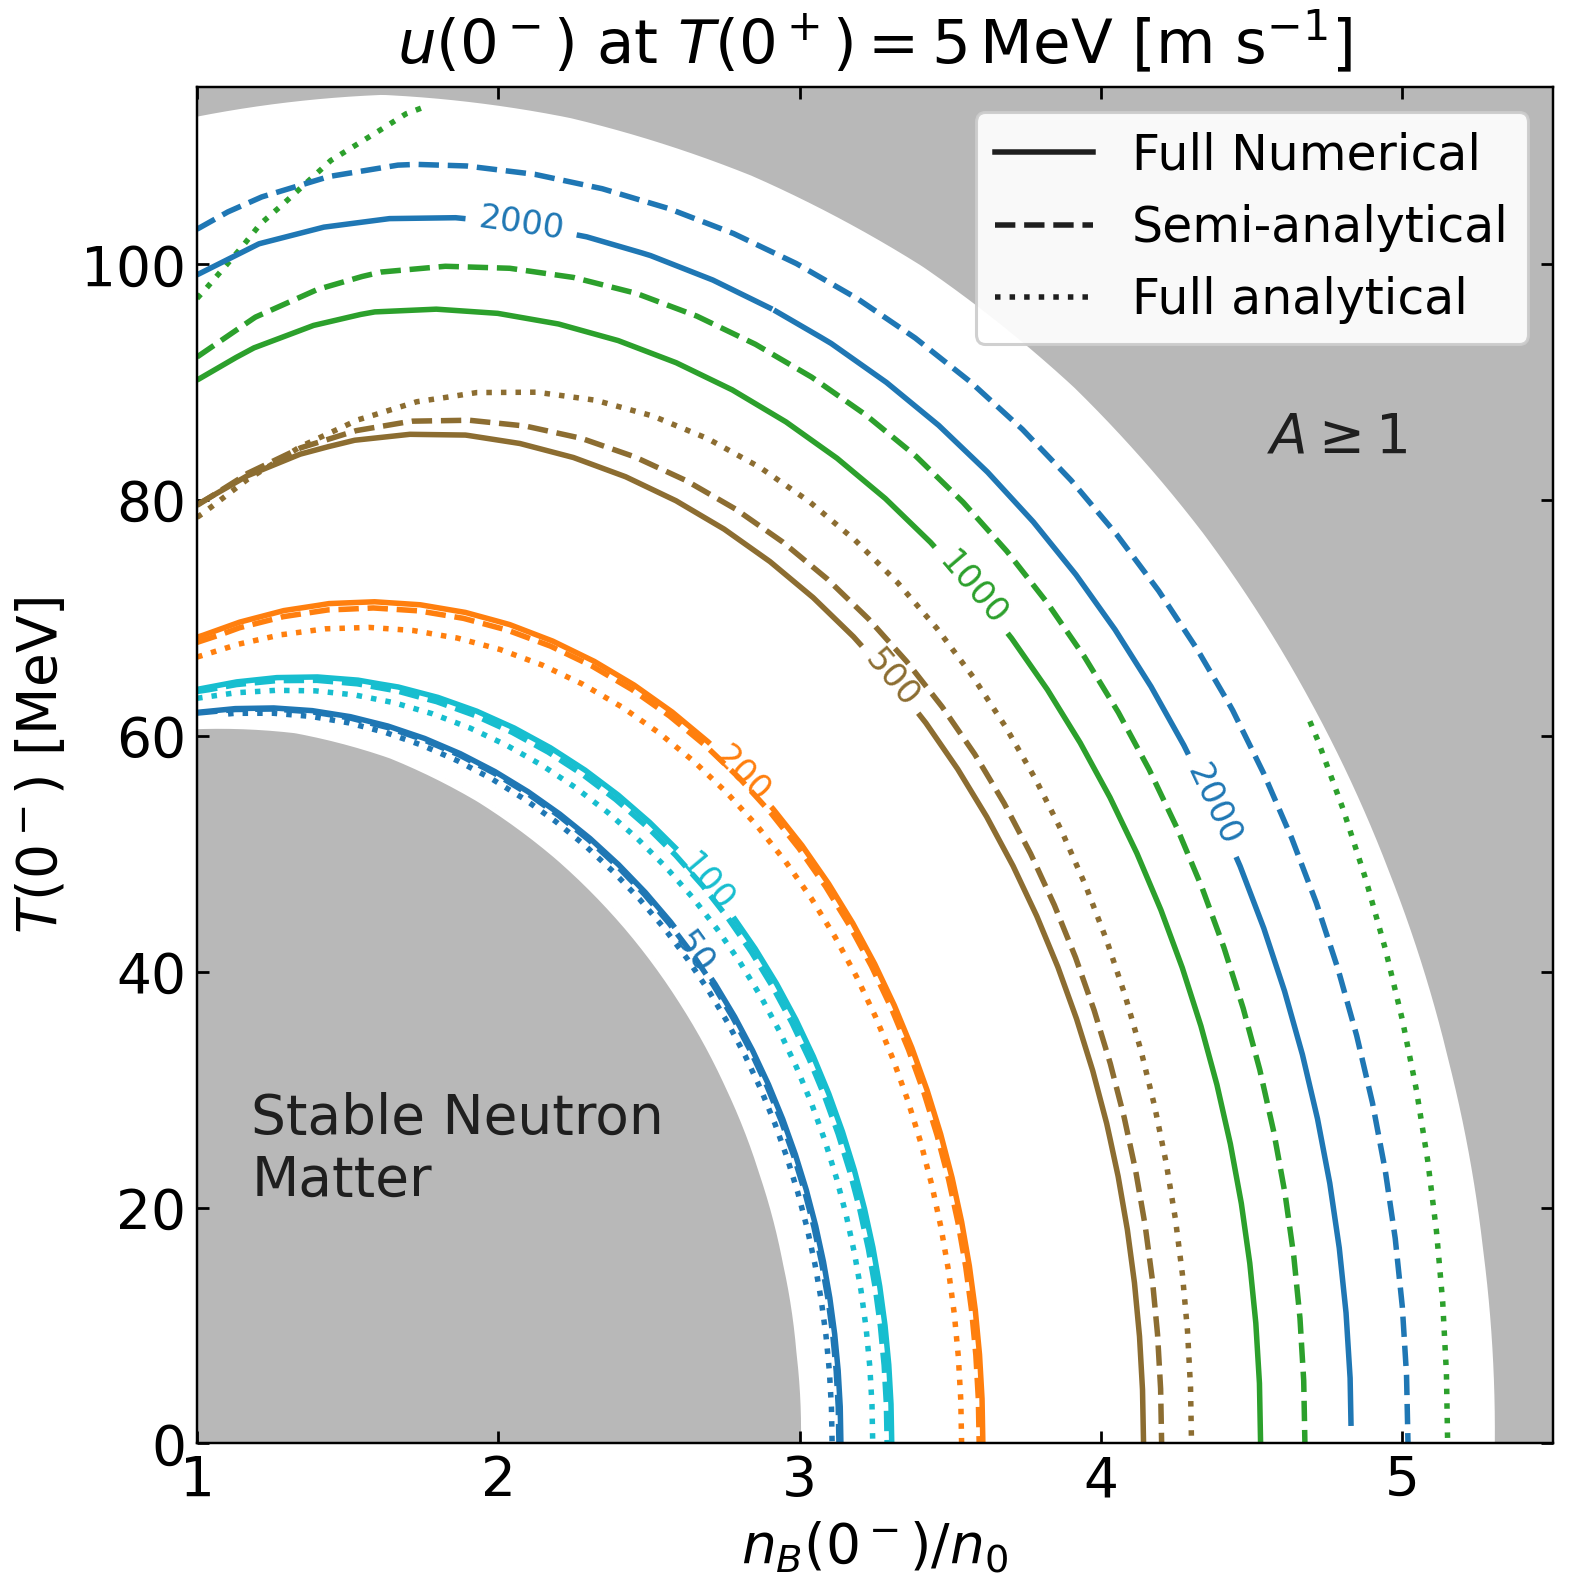

In [ ]:
# Tunable plotting parameters
CONTOUR_DOMAIN_PATH = "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-domain.npy"
FULL_ANALYTIC_PATH = "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-full-analytic-T0minus0-local-patched.npy"
SEMI_ANALYTIC_PATH = "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-semi-analytic-T0minus0-local-patched.npy"
FULL_NUMERICAL_PATH = "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-uNmax-radial-continuation-T0minus0-local-patched.npy"
T0PLUS_MEV = 5.0
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4")
NUMERICAL_LINE_STYLE = "-"
SEMI_ANALYTIC_LINE_STYLE = "--"
FULL_ANALYTIC_LINE_STYLE = ":"
NUMERICAL_LINE_WIDTH = 1.8
SEMI_ANALYTIC_LINE_WIDTH = 1.8
FULL_ANALYTIC_LINE_WIDTH = 1.8
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
BOUNDARY_INTERPOLATION_SAMPLES = 401
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
BOUNDARY_COLOR = "white"
BOUNDARY_LINE_WIDTH = 1.8
BOUNDARY_ZORDER = 1
A_REGION_TEXT = r"$A\geq1$"
A_REGION_TEXT_POSITION = (4.55, 84.0)
INNER_REGION_TEXT = "Stable Neutron\nMatter"
INNER_REGION_TEXT_POSITION = (1.18, 21.0)
REGION_TEXT_COLOR = "0.12"
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.0
TITLE = r"$u(0^-)$ at $T(0^+)=5\,\mathrm{MeV}$ [m s$^{-1}$]"
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
LEGEND_LOCATION = "upper right"
LEGEND_FONT_SIZE = 16
LEGEND_FRAME_ALPHA = 0.92
LEGEND_COLUMNS = 1
STATUS_TEXT_POSITION = (0.03, 0.97)
STATUS_TEXT_FONT_SIZE = 18
STATUS_TEXT_COLOR = "0.15"
STATUS_TEXT_BOX_COLOR = "white"
STATUS_TEXT_BOX_ALPHA = 0.85
STATUS_TEXT_BOX_PAD = 0.3
OUTPUT_PNG = "local_analysis_results/26SU-11/T0plus5-three-method-radial-continuation.png"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/State-of-the-art-contour.pdf"

from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

root = Path.cwd()
domain = np.load(root / CONTOUR_DOMAIN_PATH, allow_pickle=True).item()
full_analytic = np.load(root / FULL_ANALYTIC_PATH, allow_pickle=True).item()
semi_analytic = np.load(root / SEMI_ANALYTIC_PATH, allow_pickle=True).item()
full_numerical = np.load(root / FULL_NUMERICAL_PATH, allow_pickle=True).item()

temperature_axis = np.asarray(domain["T_0plus_values_MeV"], dtype=float)
if temperature_axis.shape != (1,) or not np.isclose(temperature_axis[0], T0PLUS_MEV):
    raise RuntimeError(f"Expected only T(0+)={T0PLUS_MEV:g} MeV, found {temperature_axis}")
for payload in (full_analytic, semi_analytic, full_numerical):
    if not np.array_equal(np.asarray(payload["T_0plus_values_MeV"], dtype=float), temperature_axis):
        raise RuntimeError("Method payloads do not share the fixed-T(0+) domain")
if not bool(full_numerical.get("run_complete", False)):
    raise RuntimeError("The selected numerical radial-continuation payload is incomplete")

boundary = domain["boundary_diagnostics"]["semi_analytic"]
transform = domain["transform"]
density_origin = float(transform["density_origin_over_n0"])
density_scale = float(transform["density_scale_over_n0"])
temperature_scale = float(transform["temperature_scale_MeV"])

def boundary_curve(records):
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta_roots = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho_roots = np.asarray([row["rho"] for row in ordered], dtype=float)
    theta = np.linspace(theta_roots[0], theta_roots[-1], BOUNDARY_INTERPOLATION_SAMPLES)
    rho = np.interp(theta, theta_roots, rho_roots)
    density = density_origin + density_scale * rho * np.cos(theta)
    temperature = temperature_scale * rho * np.sin(theta)
    return density, temperature

def velocity_grid(payload, velocity_key, success_key):
    density = np.asarray(payload["nB_0minus_over_n0_grid"], dtype=float)[:, :, 0]
    temperature = np.asarray(payload["T_0minus_MeV_grid"], dtype=float)[:, :, 0]
    velocity = np.asarray(payload[velocity_key], dtype=float)[:, :, 0]
    success = np.asarray(payload[success_key], dtype=bool)[:, :, 0]
    invalid = ~success | ~np.isfinite(density) | ~np.isfinite(temperature) | ~np.isfinite(velocity)
    return density, temperature, np.ma.masked_where(invalid, velocity)

A_density, A_temperature = boundary_curve(boundary["A_curve_records"])
inner_density, inner_temperature = boundary_curve(
    boundary["gap_curve_records_by_T0plus"][T0PLUS_MEV]
)

figure, axis = plt.subplots(
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=BACKGROUND_COLOR,
)
inner_polygon_x = np.concatenate((inner_density, (X_LIMITS[0], inner_density[0])))
inner_polygon_y = np.concatenate((inner_temperature, (Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
axis.fill(
    inner_polygon_x,
    inner_polygon_y,
    color=EXCLUDED_REGION_COLOR,
    alpha=EXCLUDED_REGION_ALPHA,
    zorder=EXCLUDED_REGION_ZORDER,
)
A_polygon_x = np.concatenate((A_density, (X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], A_density[0])))
A_polygon_y = np.concatenate((A_temperature, (Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
axis.fill(
    A_polygon_x,
    A_polygon_y,
    color=EXCLUDED_REGION_COLOR,
    alpha=EXCLUDED_REGION_ALPHA,
    zorder=EXCLUDED_REGION_ZORDER,
)
axis.plot(inner_density, inner_temperature, color=BOUNDARY_COLOR, linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)
axis.plot(A_density, A_temperature, color=BOUNDARY_COLOR, linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)

analytic_density, analytic_temperature, analytic_velocity = velocity_grid(
    full_analytic, "u_0minus_m_s_grid", "success_grid"
)
semi_density, semi_temperature, semi_velocity = velocity_grid(
    semi_analytic, "u_0minus_m_s_grid", "success_grid"
)
numerical_density, numerical_temperature, numerical_velocity = velocity_grid(
    full_numerical,
    "numerical_outward_u_0minus_m_s_grid",
    "numerical_outward_success_grid",
)
axis.contour(
    analytic_density,
    analytic_temperature,
    analytic_velocity,
    levels=VELOCITY_CONTOUR_LEVELS_M_S,
    colors=VELOCITY_CONTOUR_COLORS,
    linestyles=FULL_ANALYTIC_LINE_STYLE,
    linewidths=FULL_ANALYTIC_LINE_WIDTH,
)
axis.contour(
    semi_density,
    semi_temperature,
    semi_velocity,
    levels=VELOCITY_CONTOUR_LEVELS_M_S,
    colors=VELOCITY_CONTOUR_COLORS,
    linestyles=SEMI_ANALYTIC_LINE_STYLE,
    linewidths=SEMI_ANALYTIC_LINE_WIDTH,
)
numerical_contours = axis.contour(
    numerical_density,
    numerical_temperature,
    numerical_velocity,
    levels=VELOCITY_CONTOUR_LEVELS_M_S,
    colors=VELOCITY_CONTOUR_COLORS,
    linestyles=NUMERICAL_LINE_STYLE,
    linewidths=NUMERICAL_LINE_WIDTH,
)
axis.clabel(
    numerical_contours,
    inline=CONTOUR_LABEL_INLINE,
    fmt=CONTOUR_LABEL_FORMAT,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
)

numerical_success = np.asarray(full_numerical["numerical_outward_success"], dtype=bool)
numerical_status = np.asarray(full_numerical["numerical_outward_status"], dtype=object).ravel()
status_counts = Counter(str(value) for value in numerical_status)

axis.text(*A_REGION_TEXT_POSITION, A_REGION_TEXT, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
axis.text(*INNER_REGION_TEXT_POSITION, INNER_REGION_TEXT, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
axis.set_xlim(*X_LIMITS)
axis.set_ylim(*Y_LIMITS_MEV)
axis.set_xscale(X_SCALE)
axis.set_yscale(Y_SCALE)
axis.set_box_aspect(BOX_ASPECT)
axis.set_xlabel(r"$n_B(0^-)/n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(r"$T(0^-)$ [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
axis.tick_params(
    direction=TICK_DIRECTION,
    top=TICKS_TOP,
    right=TICKS_RIGHT,
    length=TICK_LENGTH,
    width=TICK_WIDTH,
    labelsize=TICK_LABEL_FONT_SIZE,
)
for spine in axis.spines.values():
    spine.set_linewidth(SPINE_LINE_WIDTH)

legend_handles = (
    Line2D((0.0,), (0.0,), color=REGION_TEXT_COLOR, linestyle=NUMERICAL_LINE_STYLE, linewidth=NUMERICAL_LINE_WIDTH, label=r"Full Numerical"),
    Line2D((0.0,), (0.0,), color=REGION_TEXT_COLOR, linestyle=SEMI_ANALYTIC_LINE_STYLE, linewidth=SEMI_ANALYTIC_LINE_WIDTH, label=r"Semi-analytical"),
    Line2D((0.0,), (0.0,), color=REGION_TEXT_COLOR, linestyle=FULL_ANALYTIC_LINE_STYLE, linewidth=FULL_ANALYTIC_LINE_WIDTH, label="Full analytical"),
)
axis.legend(
    handles=legend_handles,
    loc=LEGEND_LOCATION,
    ncol=LEGEND_COLUMNS,
    fontsize=LEGEND_FONT_SIZE,
    framealpha=LEGEND_FRAME_ALPHA,
)

output_png = root / OUTPUT_PNG
output_pdf = root / OUTPUT_PDF
output_png.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
figure.savefig(output_pdf, facecolor=BACKGROUND_COLOR)

print(f"Numerical accepted cells: {int(np.count_nonzero(numerical_success))}/{numerical_success.size}")
print("Numerical status counts:")
for status, count in sorted(status_counts.items()):
    print(f"  {status}: {count}")
print(f"Saved {output_png}")
plt.show()


Numerical accepted cells: 516/600
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-11/T0plus5-numerical-only.png


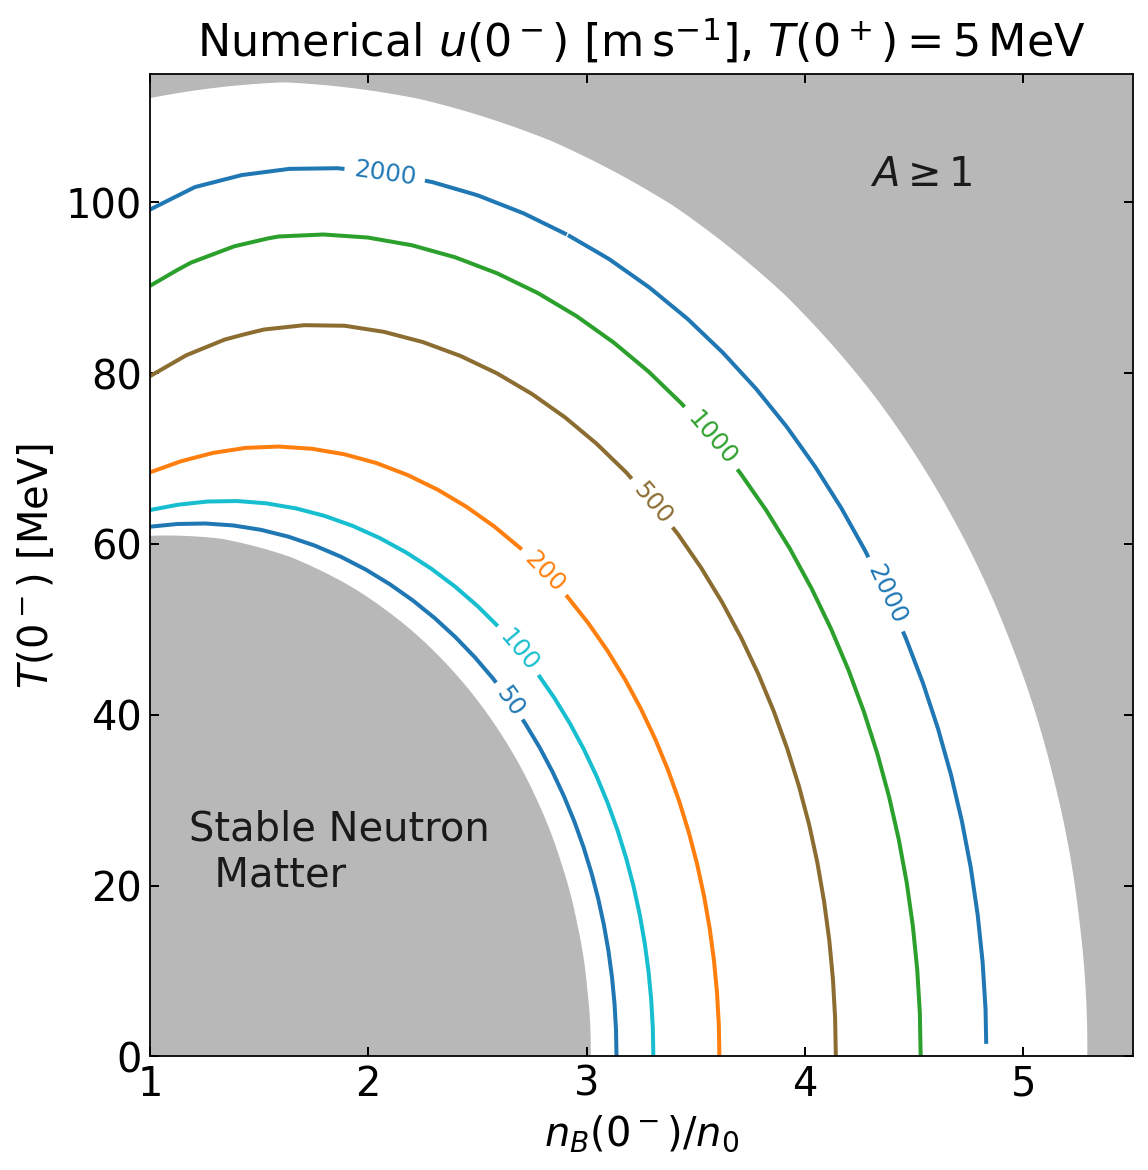

In [9]:
# Tunable plotting parameters
CONTOUR_DOMAIN_PATH = "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-domain.npy"
FULL_NUMERICAL_PATH = "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-uNmax-radial-continuation-T0minus0-local-patched.npy"
T0PLUS_MEV = 5.0
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4")
VELOCITY_CONTOUR_LINE_STYLE = "-"
VELOCITY_CONTOUR_LINE_WIDTH = 1.8
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_ZORDER = 2
BOUNDARY_INTERPOLATION_SAMPLES = 401
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
A_REGION_TEXT = r"$A\geq 1$"
A_REGION_TEXT_POSITION = (4.3, 102.0)
INNER_REGION_TEXT = "Stable Neutron \n  Matter"
INNER_REGION_TEXT_POSITION = (1.18, 20.0)
REGION_TEXT_COLOR = ".10"
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 4
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.0
TITLE = r"Numerical $u(0^-)$ [$\mathrm{m\,s^{-1}}$], $T(0^+)=5\,\mathrm{MeV}$"
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
OUTPUT_PNG = "local_analysis_results/26SU-11/T0plus5-numerical-only.png"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/Numerical-contour.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
domain = np.load(root / CONTOUR_DOMAIN_PATH, allow_pickle=True).item()
full_numerical = np.load(root / FULL_NUMERICAL_PATH, allow_pickle=True).item()

temperature_axis = np.asarray(domain["T_0plus_values_MeV"], dtype=float)
numerical_temperature_axis = np.asarray(full_numerical["T_0plus_values_MeV"], dtype=float)
if temperature_axis.shape != (1,) or not np.isclose(temperature_axis[0], T0PLUS_MEV):
    raise RuntimeError(f"Expected only T(0+)={T0PLUS_MEV:g} MeV, found {temperature_axis}")
if not np.array_equal(numerical_temperature_axis, temperature_axis):
    raise RuntimeError("The numerical payload does not share the fixed-T(0+) domain")
if not bool(full_numerical.get("run_complete", False)):
    raise RuntimeError("The selected numerical radial-continuation payload is incomplete")

boundary = domain["boundary_diagnostics"]["semi_analytic"]
transform = domain["transform"]
density_origin = float(transform["density_origin_over_n0"])
density_scale = float(transform["density_scale_over_n0"])
temperature_scale = float(transform["temperature_scale_MeV"])

def boundary_curve(records):
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta_roots = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho_roots = np.asarray([row["rho"] for row in ordered], dtype=float)
    theta = np.linspace(theta_roots[0], theta_roots[-1], BOUNDARY_INTERPOLATION_SAMPLES)
    rho = np.interp(theta, theta_roots, rho_roots)
    density = density_origin + density_scale * rho * np.cos(theta)
    temperature = temperature_scale * rho * np.sin(theta)
    return density, temperature

A_density, A_temperature = boundary_curve(boundary["A_curve_records"])
inner_density, inner_temperature = boundary_curve(
    boundary["gap_curve_records_by_T0plus"][T0PLUS_MEV]
)

density = np.asarray(full_numerical["nB_0minus_over_n0_grid"], dtype=float)[:, :, 0]
temperature = np.asarray(full_numerical["T_0minus_MeV_grid"], dtype=float)[:, :, 0]
velocity = np.asarray(full_numerical["numerical_outward_u_0minus_m_s_grid"], dtype=float)[:, :, 0]
success = np.asarray(full_numerical["numerical_outward_success_grid"], dtype=bool)[:, :, 0]
invalid = ~success | ~np.isfinite(density) | ~np.isfinite(temperature) | ~np.isfinite(velocity)
masked_velocity = np.ma.masked_where(invalid, velocity)

figure, axis = plt.subplots(
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=BACKGROUND_COLOR,
)
inner_polygon_x = np.concatenate((inner_density, (X_LIMITS[0], inner_density[0])))
inner_polygon_y = np.concatenate((inner_temperature, (Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
axis.fill(
    inner_polygon_x,
    inner_polygon_y,
    color=EXCLUDED_REGION_COLOR,
    alpha=EXCLUDED_REGION_ALPHA,
    zorder=EXCLUDED_REGION_ZORDER,
)
A_polygon_x = np.concatenate((A_density, (X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], A_density[0])))
A_polygon_y = np.concatenate((A_temperature, (Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
axis.fill(
    A_polygon_x,
    A_polygon_y,
    color=EXCLUDED_REGION_COLOR,
    alpha=EXCLUDED_REGION_ALPHA,
    zorder=EXCLUDED_REGION_ZORDER,
)
numerical_contours = axis.contour(
    density,
    temperature,
    masked_velocity,
    levels=VELOCITY_CONTOUR_LEVELS_M_S,
    colors=VELOCITY_CONTOUR_COLORS,
    linestyles=VELOCITY_CONTOUR_LINE_STYLE,
    linewidths=VELOCITY_CONTOUR_LINE_WIDTH,
    zorder=CONTOUR_ZORDER,
)
axis.clabel(
    numerical_contours,
    inline=CONTOUR_LABEL_INLINE,
    fmt=CONTOUR_LABEL_FORMAT,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
)

axis.text(
    *A_REGION_TEXT_POSITION,
    A_REGION_TEXT,
    color=REGION_TEXT_COLOR,
    fontsize=REGION_TEXT_FONT_SIZE,
    zorder=REGION_TEXT_ZORDER,
)
axis.text(
    *INNER_REGION_TEXT_POSITION,
    INNER_REGION_TEXT,
    color=REGION_TEXT_COLOR,
    fontsize=REGION_TEXT_FONT_SIZE,
    zorder=REGION_TEXT_ZORDER,
)
axis.set_xlim(*X_LIMITS)
axis.set_ylim(*Y_LIMITS_MEV)
axis.set_xscale(X_SCALE)
axis.set_yscale(Y_SCALE)
axis.set_box_aspect(BOX_ASPECT)
axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
axis.tick_params(
    direction=TICK_DIRECTION,
    top=TICKS_TOP,
    right=TICKS_RIGHT,
    length=TICK_LENGTH,
    width=TICK_WIDTH,
    labelsize=TICK_LABEL_FONT_SIZE,
)
for spine in axis.spines.values():
    spine.set_linewidth(SPINE_LINE_WIDTH)

output_png = root / OUTPUT_PNG
output_pdf = root / OUTPUT_PDF
output_png.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
figure.savefig(output_pdf, facecolor=BACKGROUND_COLOR)

print(f"Numerical accepted cells: {int(np.count_nonzero(success))}/{success.size}")
print(f"Saved {output_png}")
plt.show()


# Fixed $T(0^+)=0.1\,\mathrm{MeV}$ numerical contour

This clean panel combines the complete numerical grid through $\rho=0.84$ with a fully numerical outer bracketing shell. The outer shell uses the converged $\rho=0.86$ solution wherever it already exceeds $5000\,\mathrm{m\,s^{-1}}$ and the adaptive `26-08-24` endpoint for theta indices 7--26. All 30 angular rays therefore bracket the $5000\,\mathrm{m\,s^{-1}}$ level without interpolating failed solver cells.

Adaptive 5000 m/s brackets: 20/20
Minimum numerical outer-shell velocity: 5046.44 m/s
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-11/T0plus0p1-complete-5000-contour.png
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-11/T0plus0p1-complete-5000-contour.pdf


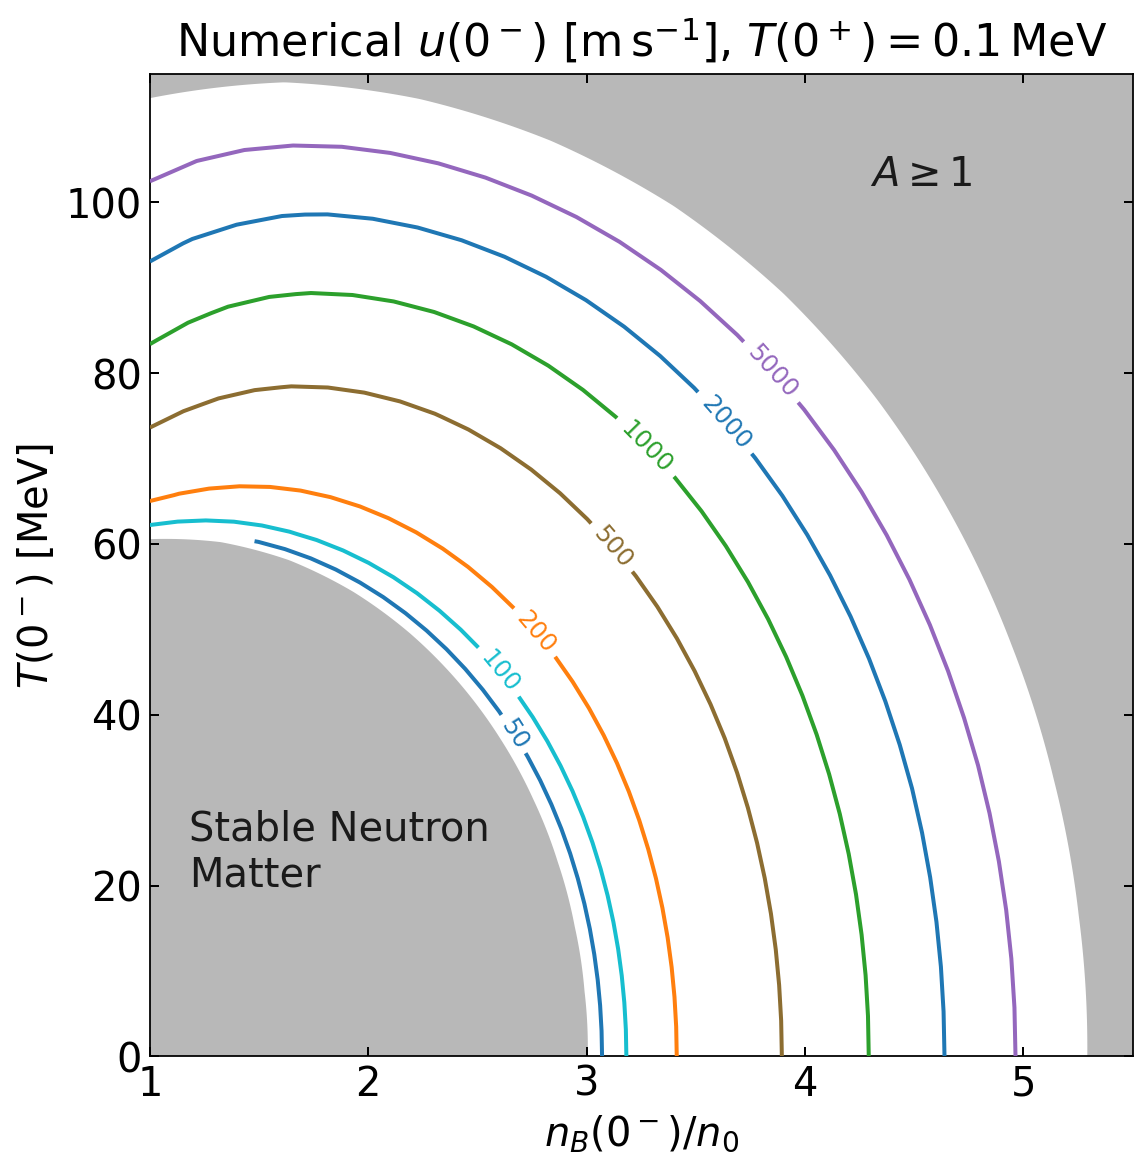

In [1]:
# Tunable plotting parameters
CONTOUR_DOMAIN_PATH = "new_paper_calculations/26-08-21/T0plus0p1-domain.npy"
FULL_NUMERICAL_PATH = "new_paper_calculations/26-08-21/T0plus0p1-uNmax-angular-wavefront.npy"
RHO086_SHELL_PATH = "new_paper_calculations/26-08-24/rho0p86_full_theta_shell/T0plus0p1-rho0p86-full-theta-shell.npy"
ADAPTIVE_BRACKET_PATH = "new_paper_calculations/26-08-24/rho5k_adaptive_bracket/T0plus0p1-rho5k-adaptive-bracket.npy"
T0PLUS_MEV = 0.1
CORE_MAX_RHO = 0.84
TARGET_CONTOUR_M_S = 5000.0
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
VELOCITY_CONTOUR_LINE_STYLE = "-"
VELOCITY_CONTOUR_LINE_WIDTH = 1.8
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_ZORDER = 3
BOUNDARY_INTERPOLATION_SAMPLES = 401
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
A_REGION_TEXT = r"$A\geq 1$"
A_REGION_TEXT_POSITION = (4.3, 102.0)
INNER_REGION_TEXT = "Stable Neutron\nMatter"
INNER_REGION_TEXT_POSITION = (1.18, 20.0)
REGION_TEXT_COLOR = "0.10"
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.0
TITLE = r"Numerical $u(0^-)$ [$\mathrm{m\,s^{-1}}$], $T(0^+)=0.1\,\mathrm{MeV}$"
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
OUTPUT_PNG = "local_analysis_results/26SU-11/T0plus0p1-complete-5000-contour.png"
OUTPUT_PDF = "local_analysis_results/26SU-11/T0plus0p1-complete-5000-contour.pdf"

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
domain = np.load(root / CONTOUR_DOMAIN_PATH, allow_pickle=True).item()
full_numerical = np.load(root / FULL_NUMERICAL_PATH, allow_pickle=True).item()
rho086_shell = np.load(root / RHO086_SHELL_PATH, allow_pickle=True).item()
adaptive_bracket = np.load(root / ADAPTIVE_BRACKET_PATH, allow_pickle=True).item()

temperature_axis = np.asarray(domain["T_0plus_values_MeV"], dtype=float)
numerical_temperature_axis = np.asarray(full_numerical["T_0plus_values_MeV"], dtype=float)
if temperature_axis.shape != (1,) or not np.isclose(temperature_axis[0], T0PLUS_MEV):
    raise RuntimeError(f"Expected only T(0+)={T0PLUS_MEV:g} MeV, found {temperature_axis}")
if not np.array_equal(numerical_temperature_axis, temperature_axis):
    raise RuntimeError("The numerical checkpoint does not share the fixed-T(0+) domain")
if not bool(rho086_shell.get("run_complete")) or not np.all(np.asarray(rho086_shell["success_grid"], dtype=bool)):
    raise RuntimeError("The rho=0.86 shell is not complete")
if not bool(adaptive_bracket.get("run_complete")):
    raise RuntimeError("The adaptive 5000 m/s bracket checkpoint is incomplete")
if not np.all(np.asarray(adaptive_bracket["accepted_5000_bracket"], dtype=bool)):
    raise RuntimeError("At least one adaptive theta ray does not exceed the acceptance velocity")

boundary = domain["boundary_diagnostics"]["semi_analytic"]
transform = domain["transform"]
density_origin = float(transform["density_origin_over_n0"])
density_scale = float(transform["density_scale_over_n0"])
temperature_scale = float(transform["temperature_scale_MeV"])

def boundary_curve(records):
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta_roots = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho_roots = np.asarray([row["rho"] for row in ordered], dtype=float)
    theta = np.linspace(theta_roots[0], theta_roots[-1], BOUNDARY_INTERPOLATION_SAMPLES)
    rho = np.interp(theta, theta_roots, rho_roots)
    density = density_origin + density_scale * rho * np.cos(theta)
    temperature = temperature_scale * rho * np.sin(theta)
    return density, temperature

A_density, A_temperature = boundary_curve(boundary["A_curve_records"])
inner_density, inner_temperature = boundary_curve(boundary["gap_curve_records_by_T0plus"][T0PLUS_MEV])
radial_axis = np.asarray(full_numerical["contour_radial_fraction_axis"], dtype=float)
core_columns = radial_axis <= CORE_MAX_RHO + 1.0e-12
density = np.asarray(full_numerical["nB_0minus_over_n0_grid"], dtype=float)[:, core_columns, 0]
temperature = np.asarray(full_numerical["T_0minus_MeV_grid"], dtype=float)[:, core_columns, 0]
velocity = np.asarray(full_numerical["numerical_outward_u_0minus_m_s_grid"], dtype=float)[:, core_columns, 0]
success = np.asarray(full_numerical["numerical_outward_success_grid"], dtype=bool)[:, core_columns, 0]
if not np.all(success):
    raise RuntimeError(f"The numerical core through rho={CORE_MAX_RHO:g} is incomplete")

rho086_records = {
    int(record["theta_index"]): record
    for record in rho086_shell["records"]
    if bool(record.get("success"))
}
expected_theta_indices = np.arange(density.shape[0], dtype=int)
if tuple(sorted(rho086_records)) != tuple(expected_theta_indices):
    raise RuntimeError("The rho=0.86 shell does not contain exactly theta indices 0-29")
outer_density = np.asarray([rho086_records[index]["nB_0minus_over_n0"] for index in expected_theta_indices], dtype=float)
outer_temperature = np.asarray([rho086_records[index]["T_0minus_MeV"] for index in expected_theta_indices], dtype=float)
outer_velocity = np.asarray(rho086_shell["u_0minus_m_s_grid"], dtype=float)[:, 0]

adaptive_records = {
    int(record["theta_index"]): record
    for record in adaptive_bracket["final_records"]
    if bool(record.get("success"))
}
adaptive_theta_indices = tuple(int(index) for index in np.asarray(adaptive_bracket["theta_indices"], dtype=int))
if tuple(sorted(adaptive_records)) != adaptive_theta_indices:
    raise RuntimeError("The adaptive checkpoint lacks a successful terminal record")
for theta_index in adaptive_theta_indices:
    record = adaptive_records[theta_index]
    outer_density[theta_index] = float(record["nB_0minus_over_n0"])
    outer_temperature[theta_index] = float(record["T_0minus_MeV"])
    outer_velocity[theta_index] = float(record["u_0minus"]) * 299_792_458.0
if not np.all(outer_velocity > TARGET_CONTOUR_M_S):
    failed_theta = np.flatnonzero(outer_velocity <= TARGET_CONTOUR_M_S)
    raise RuntimeError(f"The numerical outer shell does not bracket 5000 m/s at theta {failed_theta.tolist()}")

density = np.concatenate((density, outer_density[:, None]), axis=1)
temperature = np.concatenate((temperature, outer_temperature[:, None]), axis=1)
velocity = np.concatenate((velocity, outer_velocity[:, None]), axis=1)

figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI, constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
inner_polygon_x = np.concatenate((inner_density, (X_LIMITS[0], inner_density[0])))
inner_polygon_y = np.concatenate((inner_temperature, (Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
axis.fill(inner_polygon_x, inner_polygon_y, color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
A_polygon_x = np.concatenate((A_density, (X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], A_density[0])))
A_polygon_y = np.concatenate((A_temperature, (Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0])))
axis.fill(A_polygon_x, A_polygon_y, color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)

numerical_contours = axis.contour(
    density,
    temperature,
    velocity,
    levels=VELOCITY_CONTOUR_LEVELS_M_S,
    colors=VELOCITY_CONTOUR_COLORS,
    linestyles=VELOCITY_CONTOUR_LINE_STYLE,
    linewidths=VELOCITY_CONTOUR_LINE_WIDTH,
    zorder=CONTOUR_ZORDER,
)
axis.clabel(
    numerical_contours,
    inline=CONTOUR_LABEL_INLINE,
    fmt=CONTOUR_LABEL_FORMAT,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
)
axis.text(*A_REGION_TEXT_POSITION, A_REGION_TEXT, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
axis.text(*INNER_REGION_TEXT_POSITION, INNER_REGION_TEXT, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
axis.set_xlim(*X_LIMITS)
axis.set_ylim(*Y_LIMITS_MEV)
axis.set_xscale(X_SCALE)
axis.set_yscale(Y_SCALE)
axis.set_box_aspect(BOX_ASPECT)
axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT, length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
for spine in axis.spines.values():
    spine.set_linewidth(SPINE_LINE_WIDTH)

output_png = root / OUTPUT_PNG
output_pdf = root / OUTPUT_PDF
output_png.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
figure.savefig(output_pdf, facecolor=BACKGROUND_COLOR)
print(f"Adaptive 5000 m/s brackets: {len(adaptive_records)}/{len(adaptive_theta_indices)}")
print(f"Minimum numerical outer-shell velocity: {np.min(outer_velocity):.2f} m/s")
print(f"Saved {output_png}")
print(f"Saved {output_pdf}")
plt.show()
